In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("\nPython libraries imported successfully!")

Pandas version: 2.2.3
NumPy version: 2.4.6

Python libraries imported successfully!


In [2]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders available here:")
print(os.listdir())

Current working directory:
C:\Users\sanik\OneDrive\Desktop\IPL_Cricket_Analytics\Notebook

Files and folders available here:
['.ipynb_checkpoints', 'Day1_Dataset_Inspection.ipynb', 'IPL_Python_Analysis.ipynb']


In [3]:
from pathlib import Path

project_folder = Path.cwd().parent

print("Main project folder:", project_folder)
print("\nFolders and files inside it:")

for item in project_folder.iterdir():
    print(item.name)

Main project folder: C:\Users\sanik\OneDrive\Desktop\IPL_Cricket_Analytics

Folders and files inside it:
Data
Notebook
Outputs
Reports


In [4]:
data_folder = project_folder / "Data"

for item in data_folder.iterdir():
    print(item.name)

ipl_male_csv
ipl_male_csv.zip
outputs


In [5]:
output_data_folder = data_folder / "outputs"

for item in output_data_folder.iterdir():
    print(item.name)

final summary of team performance (2024 & 2025).csv
final summary of team performance (2024 & 2025)corrected.csv
ipl_all_matches_with_metadata.csv
sample_match_cleaned.csv
team_performance.csv


In [6]:
file_path = output_data_folder / "ipl_all_matches_with_metadata.csv"

ipl = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Number of rows:", ipl.shape[0])
print("Number of columns:", ipl.shape[1])

Dataset loaded successfully!
Number of rows: 295732
Number of columns: 34


C:\Users\sanik\AppData\Local\Temp\ipykernel_7788\35678707.py:3: DtypeWarning: Columns (17,19,20,23) have mixed types. Specify dtype option on import or set low_memory=False.
  ipl = pd.read_csv(file_path)


In [7]:
print("First 5 rows:")
display(ipl.head())

print("\nColumn names:")
print(ipl.columns.tolist())

First 5 rows:


,record_type,innings,delivery_number,batting_team,batter,non_striker,bowler,batter_runs,total_extras,wides,...,date,match_type,venue,city,toss_winner,toss_decision,winner,winner_runs,winner_wickets,player_of_match
0,ball,1,0.1,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,0,0,NaN,...,2017/04/05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh
1,ball,1,0.2,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,0,0,NaN,...,2017/04/05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh
2,ball,1,0.3,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,4,0,NaN,...,2017/04/05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh
3,ball,1,0.4,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,0,0,NaN,...,2017/04/05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh
4,ball,1,0.5,Sunrisers Hyderabad,DA Warner,S Dhawan,TS Mills,0,2,2.0,...,2017/04/05,T20,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bangalore,field,Sunrisers Hyderabad,35.0,NaN,Yuvraj Singh



Column names:
['record_type', 'innings', 'delivery_number', 'batting_team', 'batter', 'non_striker', 'bowler', 'batter_runs', 'total_extras', 'wides', 'noballs', 'byes', 'legbyes', 'penalty_runs', 'dismissal_method', 'dismissed_players', 'actual_delivery', 'non_boundary', 'fielder_1', 'fielder_2', 'fielder_3', 'source_file', 'match_id', 'season', 'date', 'match_type', 'venue', 'city', 'toss_winner', 'toss_decision', 'winner', 'winner_runs', 'winner_wickets', 'player_of_match']


In [8]:
print("DATASET INFORMATION")
ipl.info()

print("\nMISSING VALUES IN EACH COLUMN")
display(ipl.isnull().sum().to_frame(name="Missing Values"))

print("\nDUPLICATE ROWS")
print(ipl.duplicated().sum())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295732 entries, 0 to 295731
Data columns (total 34 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   record_type        295732 non-null  object 
 1   innings            295732 non-null  int64  
 2   delivery_number    295732 non-null  float64
 3   batting_team       295732 non-null  object 
 4   batter             295732 non-null  object 
 5   non_striker        295732 non-null  object 
 6   bowler             295732 non-null  object 
 7   batter_runs        295732 non-null  int64  
 8   total_extras       295732 non-null  int64  
 9   wides              9876 non-null    float64
 10  noballs            1226 non-null    float64
 11  byes               745 non-null     float64
 12  legbyes            4406 non-null    float64
 13  penalty_runs       2 non-null       float64
 14  dismissal_method   14705 non-null   object 
 15  dismissed_players  14705 non-nu

,Missing Values
record_type,0
innings,0
delivery_number,0
batting_team,0
batter,0
non_striker,0
bowler,0
batter_runs,0
total_extras,0
wides,285856



DUPLICATE ROWS
0


In [9]:
print("Record types:")
display(ipl["record_type"].value_counts())

print("\nSeasons available:")
display(
    ipl["season"]
    .astype(str)
    .value_counts()
    .sort_index()
)

print("\nNumber of unique matches:")
print(ipl["match_id"].nunique())

print("\nSeason data types:")
print(ipl["season"].map(type).value_counts())

Record types:


record_type
ball    295732
Name: count, dtype: int64


Seasons available:


season
2007/08    13489
2009       13606
2009/10    14498
2011       17013
2012       17767
2013       18177
2014       14300
2015       13652
2016       14096
2017       13862
2018       14286
2019       14312
2020/21    14559
2021       14425
2022       17912
2023       17863
2024       17103
2025       17285
2026       17527
Name: count, dtype: int64


Number of unique matches:
1243

Season data types:
season
<class 'int'>    197428
<class 'str'>     98304
Name: count, dtype: int64


In [10]:
# Standardize season values
ipl["season"] = ipl["season"].astype(str)

# Convert dates
ipl["date"] = pd.to_datetime(ipl["date"], errors="coerce")

# Compare the three seasons
three_seasons = ipl[
    ipl["season"].isin(["2024", "2025", "2026"])
]

season_summary = (
    three_seasons.groupby("season")
    .agg(
        deliveries=("match_id", "count"),
        matches=("match_id", "nunique"),
        first_match=("date", "min"),
        last_match=("date", "max")
    )
    .reset_index()
)

display(season_summary)


,season,deliveries,matches,first_match,last_match
0,2024,17103,71,2024-03-22,2024-05-26
1,2025,17285,74,2025-03-22,2025-06-03
2,2026,17527,74,2026-03-28,2026-05-31


In [11]:
# Historical data: used for analysis and model development
historical_ipl = ipl[
    ipl["season"].isin(["2024", "2025"])
].copy()

# Final testing data: reserved for 2026 prediction validation
test_ipl = ipl[
    ipl["season"] == "2026"
].copy()

print("HISTORICAL DATA (2024–2025)")
print("Deliveries:", len(historical_ipl))
print("Matches:", historical_ipl["match_id"].nunique())

print("\nFINAL TEST DATA (2026)")
print("Deliveries:", len(test_ipl))
print("Matches:", test_ipl["match_id"].nunique())

print("\nOverlapping match IDs:")
print(
    set(historical_ipl["match_id"].unique())
    .intersection(set(test_ipl["match_id"].unique()))
)

HISTORICAL DATA (2024–2025)
Deliveries: 34388
Matches: 145

FINAL TEST DATA (2026)
Deliveries: 17527
Matches: 74

Overlapping match IDs:
set()


In [12]:
match_data = (
    ipl.groupby("match_id")
    .agg(
        season=("season", "first"),
        date=("date", "first"),
        venue=("venue", "first"),
        city=("city", "first"),
        toss_winner=("toss_winner", "first"),
        toss_decision=("toss_decision", "first"),
        winner=("winner", "first"),
        player_of_match=("player_of_match", "first"),
        teams=("batting_team", "nunique"),
        innings=("innings", "nunique")
    )
    .reset_index()
)

print("Total matches:", len(match_data))
print("Total columns:", len(match_data.columns))

display(match_data.head(10))

Total matches: 1243
Total columns: 11


,match_id,season,date,venue,city,toss_winner,toss_decision,winner,player_of_match,teams,innings
0,335982,2007/08,2008-04-18,M Chinnaswamy Stadium,Bangalore,Royal Challengers Bangalore,field,Kolkata Knight Riders,BB McCullum,2,2
1,335983,2007/08,2008-04-19,"Punjab Cricket Association Stadium, Mohali",Chandigarh,Chennai Super Kings,bat,Chennai Super Kings,MEK Hussey,2,2
2,335984,2007/08,2008-04-19,Feroz Shah Kotla,Delhi,Rajasthan Royals,bat,Delhi Daredevils,MF Maharoof,2,2
3,335985,2007/08,2008-04-20,Wankhede Stadium,Mumbai,Mumbai Indians,bat,Royal Challengers Bangalore,MV Boucher,2,2
4,335986,2007/08,2008-04-20,Eden Gardens,Kolkata,Deccan Chargers,bat,Kolkata Knight Riders,DJ Hussey,2,2
5,335987,2007/08,2008-04-21,Sawai Mansingh Stadium,Jaipur,Kings XI Punjab,bat,Rajasthan Royals,SR Watson,2,2
6,335988,2007/08,2008-04-22,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Deccan Chargers,bat,Delhi Daredevils,V Sehwag,2,2
7,335989,2007/08,2008-04-23,"MA Chidambaram Stadium, Chepauk",Chennai,Mumbai Indians,field,Chennai Super Kings,ML Hayden,2,2
8,335990,2007/08,2008-04-24,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Rajasthan Royals,field,Rajasthan Royals,YK Pathan,2,2
9,335991,2007/08,2008-04-25,"Punjab Cricket Association Stadium, Mohali",Chandigarh,Mumbai Indians,field,Kings XI Punjab,KC Sangakkara,2,2


In [13]:
# Keep only our three project seasons
project_matches = match_data[
    match_data["season"].isin(["2024", "2025", "2026"])
].copy()

# Get the actual participating team names
team_details = (
    ipl[ipl["season"].isin(["2024", "2025", "2026"])]
    .groupby("match_id")["batting_team"]
    .agg(lambda x: sorted(x.unique()))
    .reset_index(name="participating_teams")
)

# Attach team names to match-level data
project_matches = project_matches.merge(
    team_details,
    on="match_id",
    how="left"
)

print("Total project matches:", len(project_matches))

print("\nMatch summary:")
display(
    project_matches.groupby("season").agg(
        matches=("match_id", "count"),
        missing_winners=("winner", lambda x: x.isna().sum()),
        matches_with_two_teams=("teams", lambda x: (x == 2).sum())
    )
)

print("\nSample match records:")
display(
    project_matches[
        ["season", "date", "participating_teams",
         "toss_winner", "toss_decision", "winner"]
    ].head(10)
)

Total project matches: 219

Match summary:


,matches,missing_winners,matches_with_two_teams
season,,,
2024,71,0,71
2025,74,4,72
2026,74,2,73



Sample match records:


,season,date,participating_teams,toss_winner,toss_decision,winner
0,2024,2024-03-22,"[Chennai Super Kings, Royal Challengers Bengal...",Royal Challengers Bengaluru,bat,Chennai Super Kings
1,2024,2024-03-23,"[Delhi Capitals, Punjab Kings]",Punjab Kings,field,Punjab Kings
2,2024,2024-03-23,"[Kolkata Knight Riders, Sunrisers Hyderabad]",Sunrisers Hyderabad,field,Kolkata Knight Riders
3,2024,2024-03-24,"[Lucknow Super Giants, Rajasthan Royals]",Rajasthan Royals,bat,Rajasthan Royals
4,2024,2024-03-24,"[Gujarat Titans, Mumbai Indians]",Mumbai Indians,field,Gujarat Titans
5,2024,2024-03-25,"[Punjab Kings, Royal Challengers Bengaluru]",Royal Challengers Bengaluru,field,Royal Challengers Bengaluru
6,2024,2024-03-26,"[Chennai Super Kings, Gujarat Titans]",Gujarat Titans,field,Chennai Super Kings
7,2024,2024-03-27,"[Mumbai Indians, Sunrisers Hyderabad]",Mumbai Indians,field,Sunrisers Hyderabad
8,2024,2024-03-28,"[Delhi Capitals, Rajasthan Royals]",Delhi Capitals,field,Rajasthan Royals
9,2024,2024-03-29,"[Kolkata Knight Riders, Royal Challengers Beng...",Kolkata Knight Riders,field,Kolkata Knight Riders


In [14]:
# Find matches with missing winners or an unexpected number of teams
unusual_matches = project_matches[
    (project_matches["winner"].isna()) |
    (project_matches["teams"] != 2)
].copy()

print("Number of unusual match records:", len(unusual_matches))

display(
    unusual_matches[
        [
            "match_id",
            "season",
            "date",
            "participating_teams",
            "teams",
            "innings",
            "toss_winner",
            "toss_decision",
            "winner"
        ]
    ].sort_values(["season", "date"])
)

Number of unusual match records: 6


,match_id,season,date,participating_teams,teams,innings,toss_winner,toss_decision,winner
102,1473469,2025,2025-04-16,"[Delhi Capitals, Rajasthan Royals]",2,4,Rajasthan Royals,field,None
114,1473481,2025,2025-04-26,"[Kolkata Knight Riders, Punjab Kings]",2,2,Punjab Kings,bat,None
125,1473492,2025,2025-05-05,[Delhi Capitals],1,1,Sunrisers Hyderabad,field,None
128,1473495,2025,2025-05-08,[Punjab Kings],1,1,Punjab Kings,bat,None
156,1527685,2026,2026-04-06,[Kolkata Knight Riders],1,1,Kolkata Knight Riders,bat,None
182,1529281,2026,2026-04-26,"[Kolkata Knight Riders, Lucknow Super Giants]",2,4,Lucknow Super Giants,field,None


In [15]:
unusual_ids = unusual_matches["match_id"].tolist()

unusual_details = (
    ipl[ipl["match_id"].isin(unusual_ids)]
    .groupby(["match_id", "season", "batting_team", "innings"])
    .agg(
        deliveries=("batter_runs", "count"),
        total_runs=("total_extras", "sum"),
        batter_runs=("batter_runs", "sum"),
        dismissals=("dismissal_method", "count")
    )
    .reset_index()
)

# Calculate total score correctly
unusual_details["total_score"] = (
    unusual_details["total_runs"] +
    unusual_details["batter_runs"]
)

display(unusual_details.sort_values(["season", "match_id", "innings"]))

,match_id,season,batting_team,innings,deliveries,total_runs,batter_runs,dismissals,total_score
0,1473469,2025,Delhi Capitals,1,128,9,179,5,188
2,1473469,2025,Rajasthan Royals,2,124,6,182,5,188
3,1473469,2025,Rajasthan Royals,3,6,1,10,2,11
1,1473469,2025,Delhi Capitals,4,4,0,13,0,13
5,1473481,2025,Punjab Kings,1,123,3,198,4,201
4,1473481,2025,Kolkata Knight Riders,2,7,2,5,0,7
6,1473492,2025,Delhi Capitals,1,123,5,128,7,133
7,1473495,2025,Punjab Kings,1,63,2,120,1,122
8,1527685,2026,Kolkata Knight Riders,1,22,0,25,2,25
9,1529281,2026,Kolkata Knight Riders,1,127,8,147,7,155


In [16]:
unusual_details = (
    ipl[ipl["match_id"].isin(unusual_ids)]
    .groupby(["match_id", "season", "batting_team", "innings"])
    .agg(
        deliveries=("actual_delivery", "count"),
        batter_runs=("batter_runs", "sum"),
        extras=("total_extras", "sum"),
        dismissals=("dismissal_method", "count")
    )
    .reset_index()
)

unusual_details["total_score"] = (
    unusual_details["batter_runs"] +
    unusual_details["extras"]
)

display(
    unusual_details.sort_values(
        ["season", "match_id", "innings"]
    )
)

,match_id,season,batting_team,innings,deliveries,batter_runs,extras,dismissals,total_score
0,1473469,2025,Delhi Capitals,1,128,179,9,5,188
2,1473469,2025,Rajasthan Royals,2,124,182,6,5,188
3,1473469,2025,Rajasthan Royals,3,6,10,1,2,11
1,1473469,2025,Delhi Capitals,4,4,13,0,0,13
5,1473481,2025,Punjab Kings,1,123,198,3,4,201
4,1473481,2025,Kolkata Knight Riders,2,7,5,2,0,7
6,1473492,2025,Delhi Capitals,1,123,128,5,7,133
7,1473495,2025,Punjab Kings,1,63,120,2,1,122
8,1527685,2026,Kolkata Knight Riders,1,22,25,0,2,25
9,1529281,2026,Kolkata Knight Riders,1,127,147,8,7,155


In [17]:
super_over_data = unusual_details[
    unusual_details["innings"].isin([3, 4])
].copy()

print("Super Over innings:")
display(
    super_over_data[
        ["match_id", "season", "batting_team",
         "innings", "total_score"]
    ].sort_values(["match_id", "innings"])
)

print("\nPotential Super Over winners:")

super_over_winners = (
    super_over_data
    .sort_values("total_score")
    .groupby("match_id")
    .tail(1)
    [["match_id", "season", "batting_team", "total_score"]]
)

display(super_over_winners)

Super Over innings:


,match_id,season,batting_team,innings,total_score
3,1473469,2025,Rajasthan Royals,3,11
1,1473469,2025,Delhi Capitals,4,13
12,1529281,2026,Lucknow Super Giants,3,1
10,1529281,2026,Kolkata Knight Riders,4,4



Potential Super Over winners:


,match_id,season,batting_team,total_score
10,1529281,2026,Kolkata Knight Riders,4
1,1473469,2025,Delhi Capitals,13


In [18]:
# Keep original winner values
project_matches["winner_resolved"] = project_matches["winner"]

# Recover winners from the Super Over results
recovered_winners = {
    1473469: "Delhi Capitals",
    1529281: "Kolkata Knight Riders"
}

project_matches["winner_resolved"] = (
    project_matches["winner_resolved"]
    .fillna(project_matches["match_id"].map(recovered_winners))
)

print("Winner status after recovery:")

display(
    project_matches.groupby("season").agg(
        total_matches=("match_id", "count"),
        original_missing=("winner", lambda x: x.isna().sum()),
        unresolved=("winner_resolved", lambda x: x.isna().sum()),
        resolved=("winner_resolved", "count")
    )
)

Winner status after recovery:


,total_matches,original_missing,unresolved,resolved
season,,,,
2024,71,0,0,71
2025,74,4,3,71
2026,74,2,1,73


In [19]:
# Identify matches whose winners are still unresolved
unresolved_matches = project_matches[
    project_matches["winner_resolved"].isna()
].copy()

print("Remaining unresolved matches:")
display(
    unresolved_matches[
        [
            "match_id",
            "season",
            "date",
            "participating_teams",
            "teams",
            "innings",
            "toss_winner",
            "toss_decision"
        ]
    ].sort_values(["season", "date"])
)

Remaining unresolved matches:


,match_id,season,date,participating_teams,teams,innings,toss_winner,toss_decision
114,1473481,2025,2025-04-26,"[Kolkata Knight Riders, Punjab Kings]",2,2,Punjab Kings,bat
125,1473492,2025,2025-05-05,[Delhi Capitals],1,1,Sunrisers Hyderabad,field
128,1473495,2025,2025-05-08,[Punjab Kings],1,1,Punjab Kings,bat
156,1527685,2026,2026-04-06,[Kolkata Knight Riders],1,1,Kolkata Knight Riders,bat


In [20]:
unresolved_ids = unresolved_matches["match_id"].tolist()

delivery_check = (
    ipl[ipl["match_id"].isin(unresolved_ids)]
    .groupby(["match_id", "season", "batting_team", "innings"])
    .agg(
        delivery_records=("actual_delivery", "count"),
        batter_runs=("batter_runs", "sum"),
        extras=("total_extras", "sum"),
        dismissals=("dismissal_method", "count")
    )
    .reset_index()
)

delivery_check["total_score"] = (
    delivery_check["batter_runs"] + delivery_check["extras"]
)

display(
    delivery_check.sort_values(
        ["season", "match_id", "innings"]
    )
)

,match_id,season,batting_team,innings,delivery_records,batter_runs,extras,dismissals,total_score
1,1473481,2025,Punjab Kings,1,123,198,3,4,201
0,1473481,2025,Kolkata Knight Riders,2,7,5,2,0,7
2,1473492,2025,Delhi Capitals,1,123,128,5,7,133
3,1473495,2025,Punjab Kings,1,63,120,2,1,122
4,1527685,2026,Kolkata Knight Riders,1,22,25,0,2,25


In [21]:
# Keep matches with a known or recovered winner
# and exactly two participating teams

verified_project_matches = project_matches[
    project_matches["winner_resolved"].notna() &
    (project_matches["teams"] == 2)
].copy()

print("Verified modelling dataset:")
print("Total matches:", len(verified_project_matches))

print("\nSeason-wise match counts:")
display(
    verified_project_matches.groupby("season").agg(
        matches=("match_id", "count"),
        unique_winners=("winner_resolved", "nunique")
    )
)

print("\nMissing winner labels:")
print(verified_project_matches["winner_resolved"].isna().sum())

Verified modelling dataset:
Total matches: 215

Season-wise match counts:


,matches,unique_winners
season,,
2024,71,10
2025,71,10
2026,73,10



Missing winner labels:
0


In [22]:
# Check whether each winner is one of the participating teams

verified_project_matches["winner_matches_teams"] = (
    verified_project_matches.apply(
        lambda row: row["winner_resolved"] in row["participating_teams"],
        axis=1
    )
)

print("Winner belongs to participating teams:")
print(
    verified_project_matches["winner_matches_teams"].value_counts()
)

print("\nInvalid winner records:")
display(
    verified_project_matches[
        verified_project_matches["winner_matches_teams"] == False
    ][
        ["match_id", "season", "participating_teams", "winner_resolved"]
    ]
)

Winner belongs to participating teams:
winner_matches_teams
True    215
Name: count, dtype: int64

Invalid winner records:


,match_id,season,participating_teams,winner_resolved


In [23]:
# Separate historical and final test matches

historical_matches = verified_project_matches[
    verified_project_matches["season"].isin(["2024", "2025"])
].copy()

test_matches = verified_project_matches[
    verified_project_matches["season"] == "2026"
].copy()

print("Historical matches (2024–2025):", len(historical_matches))
print("Final test matches (2026):", len(test_matches))

print("\nHistorical seasons:")
print(sorted(historical_matches["season"].unique()))

print("\nTest season:")
print(sorted(test_matches["season"].unique()))

# Verify there is no match ID overlap
overlap = set(historical_matches["match_id"]) & set(test_matches["match_id"])

print("\nOverlapping match IDs:", len(overlap))

Historical matches (2024–2025): 142
Final test matches (2026): 73

Historical seasons:
['2024', '2025']

Test season:
['2026']

Overlapping match IDs: 0


In [24]:
# 1. Count matches played by each team
team_played = (
    historical_matches
    .explode("participating_teams")
    .groupby("participating_teams")
    .size()
    .reset_index(name="matches_played")
    .rename(columns={"participating_teams": "team"})
)

# 2. Count matches won by each team
team_wins = (
    historical_matches
    .groupby("winner_resolved")
    .size()
    .reset_index(name="matches_won")
    .rename(columns={"winner_resolved": "team"})
)

# 3. Combine both results
team_performance = team_played.merge(
    team_wins,
    on="team",
    how="left"
)

# 4. Calculate win percentage
team_performance["matches_won"] = (
    team_performance["matches_won"].fillna(0).astype(int)
)

team_performance["win_percentage"] = (
    team_performance["matches_won"] /
    team_performance["matches_played"] * 100
)

# 5. Sort by win percentage
team_performance = team_performance.sort_values(
    "win_percentage",
    ascending=False
).reset_index(drop=True)

display(team_performance.round(2))

,team,matches_played,matches_won,win_percentage
0,Kolkata Knight Riders,26,16,61.54
1,Royal Challengers Bengaluru,30,18,60.00
2,Gujarat Titans,27,14,51.85
3,Delhi Capitals,27,14,51.85
4,Sunrisers Hyderabad,29,15,51.72
5,Punjab Kings,30,15,50.00
6,Lucknow Super Giants,28,13,46.43
7,Rajasthan Royals,29,13,44.83
8,Mumbai Indians,30,13,43.33
9,Chennai Super Kings,28,11,39.29


In [25]:
# Step 1: Keep only regular innings (1 and 2)
regular_deliveries = historical_ipl[
    historical_ipl["innings"].isin([1, 2])
].copy()

# Step 2: Calculate score for each team's innings in each match
innings_summary = (
    regular_deliveries
    .groupby(["match_id", "batting_team", "innings"])
    .agg(
        batter_runs=("batter_runs", "sum"),
        extras=("total_extras", "sum")
    )
    .reset_index()
)

# Step 3: Calculate total innings score
innings_summary["total_team_runs"] = (
    innings_summary["batter_runs"] +
    innings_summary["extras"]
)

# Step 4: Calculate team-level batting performance
team_batting = (
    innings_summary
    .groupby("batting_team")
    .agg(
        total_runs=("total_team_runs", "sum"),
        innings_played=("match_id", "count"),
        average_runs=("total_team_runs", "mean")
    )
    .reset_index()
    .rename(columns={"batting_team": "team"})
)

# Step 5: Sort by average runs
team_batting = team_batting.sort_values(
    "average_runs",
    ascending=False
).reset_index(drop=True)

display(team_batting.round(2))

,team,total_runs,innings_played,average_runs
0,Sunrisers Hyderabad,5571,29,192.10
1,Lucknow Super Giants,5215,28,186.25
2,Royal Challengers Bengaluru,5583,30,186.10
3,Gujarat Titans,4932,27,182.67
4,Mumbai Indians,5480,30,182.67
5,Rajasthan Royals,5250,29,181.03
6,Delhi Capitals,5060,28,180.71
7,Punjab Kings,5749,32,179.66
8,Chennai Super Kings,4965,28,177.32
9,Kolkata Knight Riders,4669,27,172.93


In [26]:
# 1. Calculate regular innings scores
innings_scores = (
    regular_deliveries
    .groupby(["match_id", "batting_team", "innings"])
    .agg(
        batter_runs=("batter_runs", "sum"),
        extras=("total_extras", "sum")
    )
    .reset_index()
)

innings_scores["total_runs"] = (
    innings_scores["batter_runs"] +
    innings_scores["extras"]
)

# 2. Create a match-level team mapping
match_teams = (
    innings_scores
    .groupby("match_id")["batting_team"]
    .agg(lambda x: list(x.unique()))
    .reset_index(name="teams_recorded")
)

# 3. Keep matches with exactly two recorded teams
match_teams = match_teams[
    match_teams["teams_recorded"].apply(len) == 2
].copy()

# 4. Attach team mapping
innings_scores = innings_scores.merge(
    match_teams,
    on="match_id",
    how="inner"
)

# 5. Identify the opposing team
innings_scores["bowling_team"] = innings_scores.apply(
    lambda row: [
        team for team in row["teams_recorded"]
        if team != row["batting_team"]
    ][0],
    axis=1
)

# 6. Calculate bowling performance
team_bowling = (
    innings_scores
    .groupby("bowling_team")
    .agg(
        total_runs_conceded=("total_runs", "sum"),
        bowling_innings=("match_id", "count"),
        average_runs_conceded=("total_runs", "mean")
    )
    .reset_index()
    .rename(columns={"bowling_team": "team"})
    .sort_values("average_runs_conceded")
    .reset_index(drop=True)
)

display(team_bowling.round(2))

print("Total bowling innings:", team_bowling["bowling_innings"].sum())

,team,total_runs_conceded,bowling_innings,average_runs_conceded
0,Kolkata Knight Riders,4683,27,173.44
1,Chennai Super Kings,4876,28,174.14
2,Punjab Kings,5513,31,177.84
3,Mumbai Indians,5376,30,179.20
4,Royal Challengers Bengaluru,5426,30,180.87
5,Gujarat Titans,4977,27,184.33
6,Rajasthan Royals,5430,29,187.24
7,Sunrisers Hyderabad,5467,29,188.52
8,Lucknow Super Giants,5300,28,189.29
9,Delhi Capitals,5171,27,191.52


Total bowling innings: 286


In [27]:
# Rebuild all regular innings scores before filtering
all_innings_scores = (
    regular_deliveries
    .groupby(["match_id", "batting_team", "innings"])
    .agg(
        total_runs=(
            "batter_runs", "sum"
        )
    )
    .reset_index()
)

# Count recorded innings and teams in each match
innings_validation = (
    all_innings_scores
    .groupby("match_id")
    .agg(
        recorded_innings=("innings", "count"),
        recorded_teams=("batting_team", "nunique")
    )
    .reset_index()
)

print("Total regular innings records:", len(all_innings_scores))

print("\nNumber of matches by recorded innings:")
display(
    innings_validation["recorded_innings"]
    .value_counts()
    .sort_index()
)

print("\nMatches with something other than two innings:")
display(
    innings_validation[
        innings_validation["recorded_innings"] != 2
    ]
)

Total regular innings records: 288

Number of matches by recorded innings:


recorded_innings
1      2
2    143
Name: count, dtype: int64


Matches with something other than two innings:


,match_id,recorded_innings,recorded_teams
125,1473492,1,1
128,1473495,1,1


In [28]:
# 1. Keep deliveries from verified historical matches only

verified_historical_ids = historical_matches["match_id"].unique()

clean_deliveries = historical_ipl[
    historical_ipl["match_id"].isin(verified_historical_ids) &
    historical_ipl["innings"].isin([1, 2])
].copy()

# 2. Calculate each team's score in each regular innings

clean_innings_scores = (
    clean_deliveries
    .groupby(["match_id", "batting_team", "innings"])
    .agg(
        batter_runs=("batter_runs", "sum"),
        extras=("total_extras", "sum")
    )
    .reset_index()
)

clean_innings_scores["total_runs"] = (
    clean_innings_scores["batter_runs"] +
    clean_innings_scores["extras"]
)

# 3. Validate the innings records

innings_check = (
    clean_innings_scores
    .groupby("match_id")
    .agg(
        innings_count=("innings", "count"),
        team_count=("batting_team", "nunique")
    )
)

print("Match innings validation:")
display(innings_check["innings_count"].value_counts())

# 4. Calculate batting performance

team_batting = (
    clean_innings_scores
    .groupby("batting_team")
    .agg(
        total_runs=("total_runs", "sum"),
        innings_played=("match_id", "count"),
        average_runs=("total_runs", "mean")
    )
    .reset_index()
    .rename(columns={"batting_team": "team"})
    .sort_values("average_runs", ascending=False)
    .reset_index(drop=True)
)

# 5. Identify the opposing team for every innings

team_mapping = (
    clean_innings_scores
    .groupby("match_id")["batting_team"]
    .agg(lambda x: list(x.unique()))
    .reset_index(name="teams")
)

clean_innings_scores = clean_innings_scores.merge(
    team_mapping,
    on="match_id",
    how="left"
)

clean_innings_scores["bowling_team"] = (
    clean_innings_scores.apply(
        lambda row: next(
            team for team in row["teams"]
            if team != row["batting_team"]
        ),
        axis=1
    )
)

# 6. Calculate bowling performance

team_bowling = (
    clean_innings_scores
    .groupby("bowling_team")
    .agg(
        total_runs_conceded=("total_runs", "sum"),
        bowling_innings=("match_id", "count"),
        average_runs_conceded=("total_runs", "mean")
    )
    .reset_index()
    .rename(columns={"bowling_team": "team"})
    .sort_values("average_runs_conceded")
    .reset_index(drop=True)
)

print("\nCorrected batting performance:")
display(team_batting.round(2))

print("\nCorrected bowling performance:")
display(team_bowling.round(2))

print("\nTotal batting innings:", team_batting["innings_played"].sum())
print("Total bowling innings:", team_bowling["bowling_innings"].sum())

Match innings validation:


innings_count
2    142
Name: count, dtype: int64


Corrected batting performance:


,team,total_runs,innings_played,average_runs
0,Sunrisers Hyderabad,5571,29,192.10
1,Lucknow Super Giants,5215,28,186.25
2,Royal Challengers Bengaluru,5583,30,186.10
3,Gujarat Titans,4932,27,182.67
4,Mumbai Indians,5480,30,182.67
5,Delhi Capitals,4927,27,182.48
6,Rajasthan Royals,5250,29,181.03
7,Punjab Kings,5426,30,180.87
8,Kolkata Knight Riders,4662,26,179.31
9,Chennai Super Kings,4965,28,177.32



Corrected bowling performance:


,team,total_runs_conceded,bowling_innings,average_runs_conceded
0,Kolkata Knight Riders,4482,26,172.38
1,Chennai Super Kings,4876,28,174.14
2,Mumbai Indians,5376,30,179.20
3,Royal Challengers Bengaluru,5426,30,180.87
4,Punjab Kings,5506,30,183.53
5,Gujarat Titans,4977,27,184.33
6,Rajasthan Royals,5430,29,187.24
7,Sunrisers Hyderabad,5467,29,188.52
8,Lucknow Super Giants,5300,28,189.29
9,Delhi Capitals,5171,27,191.52



Total batting innings: 284
Total bowling innings: 284


In [29]:
# Combine historical team performance metrics

team_features = (
    team_performance[
        ["team", "matches_played", "matches_won", "win_percentage"]
    ]
    .merge(
        team_batting[["team", "average_runs"]],
        on="team",
        how="inner"
    )
    .merge(
        team_bowling[["team", "average_runs_conceded"]],
        on="team",
        how="inner"
    )
)

team_features = team_features.sort_values(
    "win_percentage",
    ascending=False
).reset_index(drop=True)

display(team_features.round(2))

print("\nNumber of teams:", len(team_features))

,team,matches_played,matches_won,win_percentage,average_runs,average_runs_conceded
0,Kolkata Knight Riders,26,16,61.54,179.31,172.38
1,Royal Challengers Bengaluru,30,18,60.00,186.10,180.87
2,Gujarat Titans,27,14,51.85,182.67,184.33
3,Delhi Capitals,27,14,51.85,182.48,191.52
4,Sunrisers Hyderabad,29,15,51.72,192.10,188.52
5,Punjab Kings,30,15,50.00,180.87,183.53
6,Lucknow Super Giants,28,13,46.43,186.25,189.29
7,Rajasthan Royals,29,13,44.83,181.03,187.24
8,Mumbai Indians,30,13,43.33,182.67,179.20
9,Chennai Super Kings,28,11,39.29,177.32,174.14



Number of teams: 10


In [30]:
# Prepare historical match results for recent-form analysis

recent_matches = historical_matches[
    ["match_id", "date", "participating_teams", "winner_resolved"]
].copy()

# Create one row per team per match
recent_matches = recent_matches.explode("participating_teams")

recent_matches = recent_matches.rename(
    columns={"participating_teams": "team"}
)

# Mark whether the team won
recent_matches["result"] = np.where(
    recent_matches["team"] == recent_matches["winner_resolved"],
    "Win",
    "Loss"
)

# Sort matches chronologically
recent_matches = recent_matches.sort_values(
    ["team", "date"]
)

display(recent_matches.head(10))

,match_id,date,team,winner_resolved,result
0,1422119,2024-03-22,Chennai Super Kings,Chennai Super Kings,Win
6,1422125,2024-03-26,Chennai Super Kings,Chennai Super Kings,Win
12,1422131,2024-03-31,Chennai Super Kings,Delhi Capitals,Loss
17,1422136,2024-04-05,Chennai Super Kings,Sunrisers Hyderabad,Loss
21,1426260,2024-04-08,Chennai Super Kings,Chennai Super Kings,Win
28,1426267,2024-04-14,Chennai Super Kings,Chennai Super Kings,Win
33,1426272,2024-04-19,Chennai Super Kings,Lucknow Super Giants,Loss
38,1426277,2024-04-23,Chennai Super Kings,Lucknow Super Giants,Loss
45,1426284,2024-04-28,Chennai Super Kings,Chennai Super Kings,Win
48,1426287,2024-05-01,Chennai Super Kings,Punjab Kings,Loss


In [31]:
# Get each team's five most recent matches

last_five_matches = (
    recent_matches
    .sort_values(["team", "date"])
    .groupby("team")
    .tail(5)
    .copy()
)

# Calculate wins and matches played
recent_form = (
    last_five_matches
    .groupby("team")
    .agg(
        last_5_wins=("result", lambda x: (x == "Win").sum()),
        matches_considered=("result", "count")
    )
    .reset_index()
)

# Calculate recent win percentage
recent_form["last_5_win_percentage"] = (
    recent_form["last_5_wins"] /
    recent_form["matches_considered"] * 100
)

recent_form = recent_form.sort_values(
    "last_5_win_percentage",
    ascending=False
).reset_index(drop=True)

display(recent_form.round(2))

,team,last_5_wins,matches_considered,last_5_win_percentage
0,Sunrisers Hyderabad,4,5,80.0
1,Royal Challengers Bengaluru,4,5,80.0
2,Rajasthan Royals,2,5,40.0
3,Chennai Super Kings,2,5,40.0
4,Gujarat Titans,2,5,40.0
5,Kolkata Knight Riders,2,5,40.0
6,Punjab Kings,2,5,40.0
7,Mumbai Indians,2,5,40.0
8,Delhi Capitals,1,5,20.0
9,Lucknow Super Giants,1,5,20.0


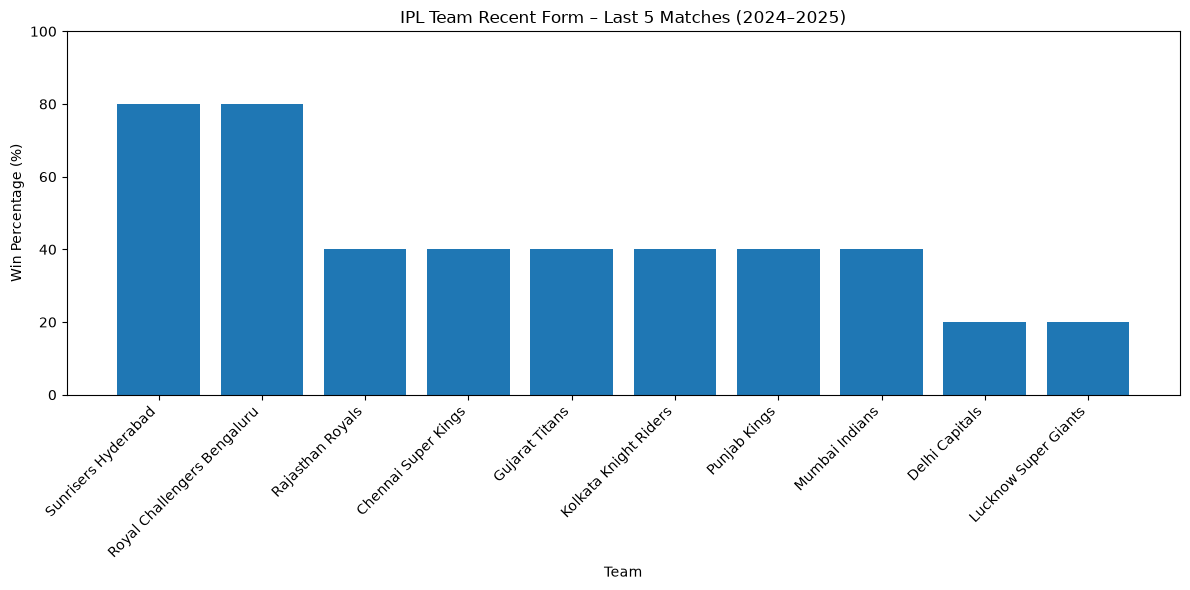

In [32]:
plt.figure(figsize=(12, 6))

plt.bar(
    recent_form["team"],
    recent_form["last_5_win_percentage"]
)

plt.title("IPL Team Recent Form – Last 5 Matches (2024–2025)")
plt.xlabel("Team")
plt.ylabel("Win Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [33]:
# Count matches played at each venue during 2024–2025

venue_summary = (
    historical_matches
    .groupby("venue")
    .agg(
        matches_played=("match_id", "nunique"),
        unique_winners=("winner_resolved", "nunique")
    )
    .reset_index()
    .sort_values("matches_played", ascending=False)
)

display(venue_summary)

print("Total venues:", venue_summary["venue"].nunique())

,venue,matches_played,unique_winners
10,"Narendra Modi Stadium, Ahmedabad",17,8
2,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,15,8
7,"MA Chidambaram Stadium, Chepauk, Chennai",15,7
13,"Wankhede Stadium, Mumbai",14,7
4,"Eden Gardens, Kolkata",13,7
0,"Arun Jaitley Stadium, Delhi",12,7
12,"Sawai Mansingh Stadium, Jaipur",12,7
6,"M Chinnaswamy Stadium, Bengaluru",12,7
11,"Rajiv Gandhi International Stadium, Uppal, Hyd...",11,5
8,Maharaja Yadavindra Singh International Cricke...,10,6


Total venues: 14


In [34]:
# Expand each match into one row per participating team

venue_matches = historical_matches[
    ["match_id", "venue", "participating_teams", "winner_resolved"]
].explode("participating_teams")

venue_matches = venue_matches.rename(
    columns={"participating_teams": "team"}
)

# Identify team wins
venue_matches["won"] = (
    venue_matches["team"] == venue_matches["winner_resolved"]
).astype(int)

# Calculate team performance at each venue
team_venue_performance = (
    venue_matches
    .groupby(["venue", "team"])
    .agg(
        matches_played=("match_id", "nunique"),
        matches_won=("won", "sum")
    )
    .reset_index()
)

team_venue_performance["win_percentage"] = (
    team_venue_performance["matches_won"] /
    team_venue_performance["matches_played"] * 100
)

team_venue_performance = team_venue_performance.sort_values(
    ["venue", "win_percentage"],
    ascending=[True, False]
).reset_index(drop=True)

display(team_venue_performance.round(2))


,venue,team,matches_played,matches_won,win_percentage
0,"Arun Jaitley Stadium, Delhi",Royal Challengers Bengaluru,1,1,100.0
1,"Arun Jaitley Stadium, Delhi",Sunrisers Hyderabad,2,2,100.0
2,"Arun Jaitley Stadium, Delhi",Delhi Capitals,10,5,50.0
3,"Arun Jaitley Stadium, Delhi",Gujarat Titans,2,1,50.0
4,"Arun Jaitley Stadium, Delhi",Kolkata Knight Riders,2,1,50.0
...,...,...,...,...,...
101,"Wankhede Stadium, Mumbai",Kolkata Knight Riders,2,1,50.0
102,"Wankhede Stadium, Mumbai",Lucknow Super Giants,2,1,50.0
103,"Wankhede Stadium, Mumbai",Royal Challengers Bengaluru,2,1,50.0
104,"Wankhede Stadium, Mumbai",Delhi Capitals,2,0,0.0


In [35]:
# Keep venues where a team has played at least 3 matches

reliable_venue_performance = team_venue_performance[
    team_venue_performance["matches_played"] >= 3
].copy()

# Find each team's highest win percentage
strongest_venues = (
    reliable_venue_performance
    .sort_values(
        ["team", "win_percentage", "matches_played"],
        ascending=[True, False, False]
    )
    .groupby("team")
    .head(1)
    .reset_index(drop=True)
)

display(strongest_venues.round(2))

,venue,team,matches_played,matches_won,win_percentage
0,"MA Chidambaram Stadium, Chepauk, Chennai",Chennai Super Kings,13,6,46.15
1,Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket St...,Delhi Capitals,4,3,75.00
2,"Narendra Modi Stadium, Ahmedabad",Gujarat Titans,13,7,53.85
3,"MA Chidambaram Stadium, Chepauk, Chennai",Kolkata Knight Riders,3,2,66.67
4,Bharat Ratna Shri Atal Bihari Vajpayee Ekana C...,Lucknow Super Giants,14,6,42.86
5,"Wankhede Stadium, Mumbai",Mumbai Indians,14,8,57.14
6,"Narendra Modi Stadium, Ahmedabad",Punjab Kings,4,3,75.00
7,"Sawai Mansingh Stadium, Jaipur",Rajasthan Royals,10,5,50.00
8,"Narendra Modi Stadium, Ahmedabad",Royal Challengers Bengaluru,3,2,66.67
9,"Rajiv Gandhi International Stadium, Uppal, Hyd...",Sunrisers Hyderabad,11,7,63.64


In [36]:
# Define IPL teams and their primary home venues

home_venues = {
    "Chennai Super Kings": "MA Chidambaram Stadium, Chepauk, Chennai",
    "Mumbai Indians": "Wankhede Stadium, Mumbai",
    "Royal Challengers Bengaluru": "M Chinnaswamy Stadium, Bengaluru",
    "Kolkata Knight Riders": "Eden Gardens, Kolkata",
    "Delhi Capitals": "Arun Jaitley Stadium, Delhi",
    "Punjab Kings": "Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur",
    "Rajasthan Royals": "Sawai Mansingh Stadium, Jaipur",
    "Sunrisers Hyderabad": "Rajiv Gandhi International Stadium, Uppal, Hyderabad",
    "Gujarat Titans": "Narendra Modi Stadium, Ahmedabad",
    "Lucknow Super Giants": "Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow"
}

print("Number of teams:", len(home_venues))

for team, venue in home_venues.items():
    print(team, "->", venue)

Number of teams: 10
Chennai Super Kings -> MA Chidambaram Stadium, Chepauk, Chennai
Mumbai Indians -> Wankhede Stadium, Mumbai
Royal Challengers Bengaluru -> M Chinnaswamy Stadium, Bengaluru
Kolkata Knight Riders -> Eden Gardens, Kolkata
Delhi Capitals -> Arun Jaitley Stadium, Delhi
Punjab Kings -> Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur
Rajasthan Royals -> Sawai Mansingh Stadium, Jaipur
Sunrisers Hyderabad -> Rajiv Gandhi International Stadium, Uppal, Hyderabad
Gujarat Titans -> Narendra Modi Stadium, Ahmedabad
Lucknow Super Giants -> Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow


In [37]:
# Check whether each team's home venue exists in the dataset

for team, home_venue in home_venues.items():

    venue_exists = (
        historical_matches["venue"] == home_venue
    ).any()

    print(
        team,
        "->",
        "Matched" if venue_exists else "Not matched",
        "|",
        home_venue
    )

Chennai Super Kings -> Matched | MA Chidambaram Stadium, Chepauk, Chennai
Mumbai Indians -> Matched | Wankhede Stadium, Mumbai
Royal Challengers Bengaluru -> Matched | M Chinnaswamy Stadium, Bengaluru
Kolkata Knight Riders -> Matched | Eden Gardens, Kolkata
Delhi Capitals -> Matched | Arun Jaitley Stadium, Delhi
Punjab Kings -> Matched | Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur
Rajasthan Royals -> Matched | Sawai Mansingh Stadium, Jaipur
Sunrisers Hyderabad -> Matched | Rajiv Gandhi International Stadium, Uppal, Hyderabad
Gujarat Titans -> Matched | Narendra Modi Stadium, Ahmedabad
Lucknow Super Giants -> Matched | Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow


In [38]:
# Create one row per team per match

home_analysis = historical_matches[
    ["match_id", "date", "venue", "participating_teams", "winner_resolved"]
].explode("participating_teams")

home_analysis = home_analysis.rename(
    columns={"participating_teams": "team"}
)

# Map each team's primary home venue
home_analysis["home_venue"] = home_analysis["team"].map(home_venues)

# Classify home and away/other matches
home_analysis["match_location"] = np.where(
    home_analysis["venue"] == home_analysis["home_venue"],
    "Home",
    "Away/Other"
)

# Identify wins
home_analysis["won"] = (
    home_analysis["team"] == home_analysis["winner_resolved"]
).astype(int)

# Calculate performance
home_away_performance = (
    home_analysis
    .groupby(["team", "match_location"])
    .agg(
        matches_played=("match_id", "nunique"),
        matches_won=("won", "sum")
    )
    .reset_index()
)

home_away_performance["win_percentage"] = (
    home_away_performance["matches_won"] /
    home_away_performance["matches_played"] * 100
)

display(home_away_performance.round(2))

,team,match_location,matches_played,matches_won,win_percentage
0,Chennai Super Kings,Away/Other,15,5,33.33
1,Chennai Super Kings,Home,13,6,46.15
2,Delhi Capitals,Away/Other,17,9,52.94
3,Delhi Capitals,Home,10,5,50.00
4,Gujarat Titans,Away/Other,14,7,50.00
5,Gujarat Titans,Home,13,7,53.85
6,Kolkata Knight Riders,Away/Other,13,9,69.23
7,Kolkata Knight Riders,Home,13,7,53.85
8,Lucknow Super Giants,Away/Other,14,7,50.00
9,Lucknow Super Giants,Home,14,6,42.86


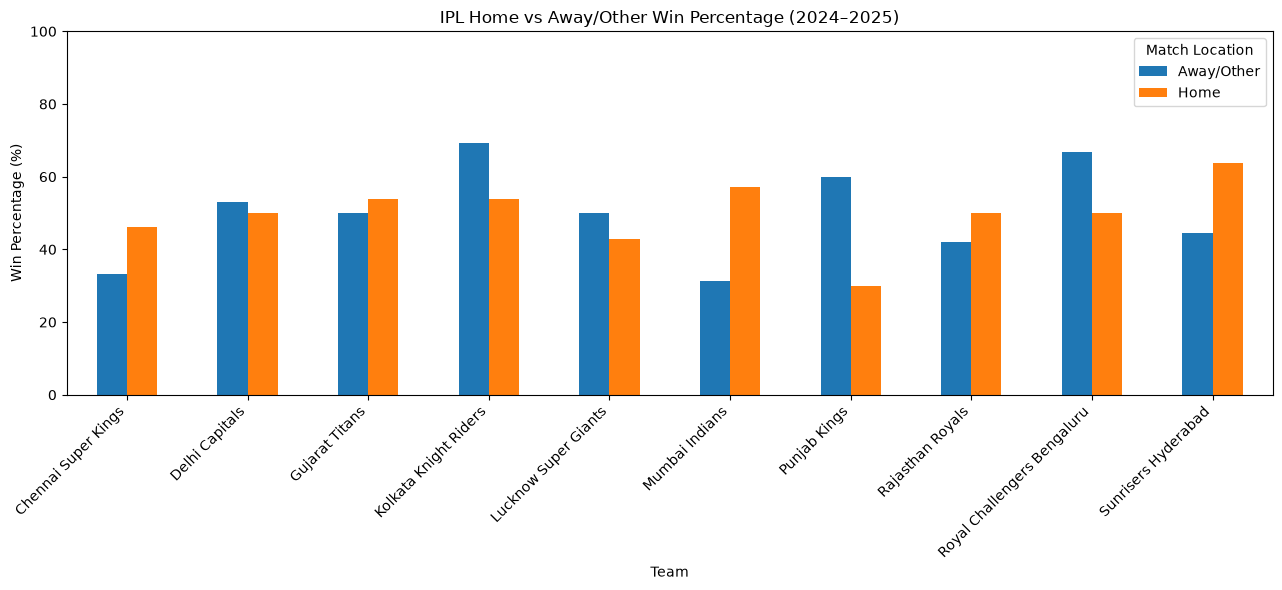

In [39]:
home_away_pivot = home_away_performance.pivot(
    index="team",
    columns="match_location",
    values="win_percentage"
)

home_away_pivot.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("IPL Home vs Away/Other Win Percentage (2024–2025)")
plt.xlabel("Team")
plt.ylabel("Win Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 100)
plt.legend(title="Match Location")
plt.tight_layout()
plt.show()

In [40]:
# Analyze toss winner vs match winner

toss_analysis = historical_matches[
    ["match_id", "toss_winner", "toss_decision", "winner_resolved"]
].copy()

# Identify whether toss winner also won the match
toss_analysis["toss_winner_won_match"] = (
    toss_analysis["toss_winner"] ==
    toss_analysis["winner_resolved"]
)

# Summarize results
toss_result = (
    toss_analysis
    .groupby("toss_winner_won_match")
    .size()
    .reset_index(name="matches")
)

toss_result["percentage"] = (
    toss_result["matches"] /
    len(toss_analysis) * 100
)

display(toss_result)

print("Total matches analyzed:", len(toss_analysis))

,toss_winner_won_match,matches,percentage
0,False,68,47.887324
1,True,74,52.112676


Total matches analyzed: 142


In [41]:
# Analyze toss decision and match outcomes

toss_decision_analysis = (
    toss_analysis
    .groupby("toss_decision")
    .agg(
        total_matches=("match_id", "count"),
        toss_winner_match_wins=("toss_winner_won_match", "sum")
    )
    .reset_index()
)

toss_decision_analysis["win_percentage"] = (
    toss_decision_analysis["toss_winner_match_wins"] /
    toss_decision_analysis["total_matches"] * 100
)

display(toss_decision_analysis.round(2))

,toss_decision,total_matches,toss_winner_match_wins,win_percentage
0,bat,31,16,51.61
1,field,111,58,52.25


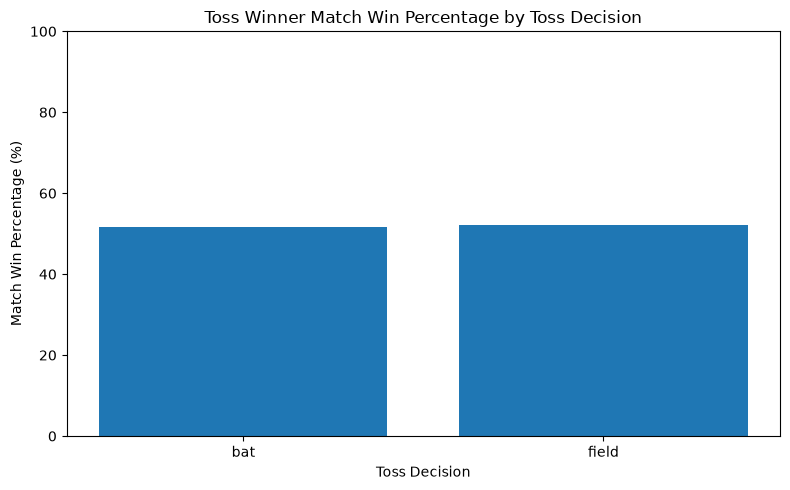

In [42]:
plt.figure(figsize=(8, 5))

plt.bar(
    toss_decision_analysis["toss_decision"],
    toss_decision_analysis["win_percentage"]
)

plt.title("Toss Winner Match Win Percentage by Toss Decision")
plt.xlabel("Toss Decision")
plt.ylabel("Match Win Percentage (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [43]:
# Identify the team batting first in each match

first_innings_teams = (
    ipl[
        ipl["match_id"].isin(historical_matches["match_id"]) &
        (ipl["innings"] == 1)
    ]
    .groupby("match_id")["batting_team"]
    .first()
    .reset_index(name="batting_first_team")
)

# Merge with match results
batting_order_analysis = historical_matches[
    ["match_id", "winner_resolved"]
].merge(
    first_innings_teams,
    on="match_id",
    how="inner"
)

# Classify match winner
batting_order_analysis["winning_type"] = np.where(
    batting_order_analysis["winner_resolved"] ==
    batting_order_analysis["batting_first_team"],
    "Batting First",
    "Chasing"
)

# Calculate results
batting_order_summary = (
    batting_order_analysis
    .groupby("winning_type")
    .agg(
        matches_won=("match_id", "count")
    )
    .reset_index()
)

batting_order_summary["win_percentage"] = (
    batting_order_summary["matches_won"] /
    len(batting_order_analysis) * 100
)

display(batting_order_summary.round(2))

print("Total matches analyzed:", len(batting_order_analysis))

,winning_type,matches_won,win_percentage
0,Batting First,69,48.59
1,Chasing,73,51.41


Total matches analyzed: 142


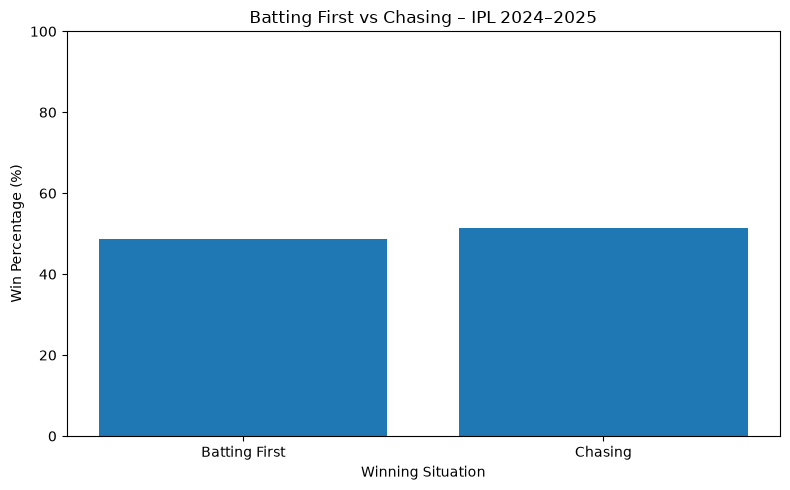

In [44]:
plt.figure(figsize=(8, 5))

plt.bar(
    batting_order_summary["winning_type"],
    batting_order_summary["win_percentage"]
)

plt.title("Batting First vs Chasing – IPL 2024–2025")
plt.xlabel("Winning Situation")
plt.ylabel("Win Percentage (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [46]:
# Inspect dismissal methods in historical matches

dismissal_summary = (
    batting_data[
        batting_data["dismissal_method"].notna()
    ]
    ["dismissal_method"]
    .value_counts()
    .reset_index()
)

dismissal_summary.columns = [
    "dismissal_method",
    "count"
]

display(dismissal_summary)

NameError: name 'batting_data' is not defined

In [ ]:
# Inspect player names recorded in dismissal events

dismissal_records = batting_data[
    batting_data["dismissal_method"].notna()
][
    ["batter", "dismissal_method", "dismissed_players"]
]

display(dismissal_records.head(15))

In [ ]:
# Dismissals that count against batting average
valid_dismissals = [
    "caught",
    "bowled",
    "lbw",
    "run out",
    "caught and bowled",
    "stumped",
    "hit wicket",
    "retired out",
    "obstructing the field"
]

# Extract valid dismissal records
dismissed_data = batting_data[
    batting_data["dismissal_method"].isin(valid_dismissals)
].copy()

# Count dismissals against the correct batter
batter_dismissals = (
    dismissed_data
    .groupby("dismissed_players")
    .size()
    .reset_index(name="times_dismissed")
    .rename(columns={"dismissed_players": "batter"})
)

# Merge dismissal counts with batting performance
batter_performance = batter_performance.merge(
    batter_dismissals,
    on="batter",
    how="left"
)

batter_performance["times_dismissed"] = (
    batter_performance["times_dismissed"].fillna(0)
)

# Calculate batting average
batter_performance["batting_average"] = (
    batter_performance["total_runs"] /
    batter_performance["times_dismissed"].replace(0, np.nan)
)

# Display top 15 run scorers
top_batters = (
    batter_performance
    .sort_values("total_runs", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

display(top_batters.round(2))

In [ ]:
# Top 15 batters by strike rate
top_strike_rate = (
    batter_performance[
        batter_performance["balls_faced"] >= 100
    ]
    .sort_values("strike_rate", ascending=False)
    .head(15)
    .reset_index(drop=True)
)

display(
    top_strike_rate[
        [
            "batter",
            "total_runs",
            "balls_faced",
            "strike_rate",
            "batting_average"
        ]
    ].round(2)
)

In [ ]:
top_10_strike_rate = top_strike_rate.head(10)

plt.figure(figsize=(12, 6))

plt.bar(
    top_10_strike_rate["batter"],
    top_10_strike_rate["strike_rate"]
)

plt.title("Top 10 IPL Batters by Strike Rate (2024–2025)")
plt.xlabel("Batter")
plt.ylabel("Strike Rate")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [ ]:
# Inspect delivery numbering

print("Delivery number data type:")
print(batting_data["delivery_number"].dtype)

print("\nSample delivery numbers:")
print(
    batting_data[
        ["match_id", "innings", "delivery_number", "batter", "batter_runs"]
    ].head(20)
)

print("\nMinimum delivery number:")
print(batting_data["delivery_number"].min())

print("\nMaximum delivery number:")
print(batting_data["delivery_number"].max())

In [ ]:
# Extract the over number from delivery_number
batting_data["over_number"] = (
    batting_data["delivery_number"].astype(int)
)

# Classify each delivery into an innings phase
batting_data["phase"] = np.select(
    [
        batting_data["over_number"].between(0, 5),
        batting_data["over_number"].between(6, 14),
        batting_data["over_number"].between(15, 19)
    ],
    [
        "Powerplay",
        "Middle Overs",
        "Death Overs"
    ],
    default="Other"
)

# Check phase classification
display(
    batting_data[
        ["delivery_number", "over_number", "batter", "batter_runs", "phase"]
    ].head(20)
)

In [ ]:
# Count balls faced (wides do not count)
batting_data["ball_faced"] = (
    batting_data["wides"].fillna(0) == 0
).astype(int)

# Calculate runs, balls and matches for each batter in each phase
phase_batting = (
    batting_data[batting_data["phase"] != "Other"]
    .groupby(["phase", "batter"])
    .agg(
        total_runs=("batter_runs", "sum"),
        balls_faced=("ball_faced", "sum"),
        matches_played=("match_id", "nunique")
    )
    .reset_index()
)

# Calculate strike rate
phase_batting["strike_rate"] = (
    phase_batting["total_runs"] /
    phase_batting["balls_faced"].replace(0, np.nan) * 100
)

# Count dismissals in each phase
valid_dismissals = [
    "caught", "bowled", "lbw", "run out",
    "caught and bowled", "stumped", "hit wicket",
    "retired out", "obstructing the field"
]

phase_dismissals = (
    batting_data[
        (batting_data["phase"] != "Other") &
        (batting_data["dismissal_method"].isin(valid_dismissals))
    ]
    .groupby(["phase", "dismissed_players"])
    .size()
    .reset_index(name="times_dismissed")
    .rename(columns={"dismissed_players": "batter"})
)

phase_batting = phase_batting.merge(
    phase_dismissals,
    on=["phase", "batter"],
    how="left"
)

phase_batting["times_dismissed"] = (
    phase_batting["times_dismissed"].fillna(0)
)

phase_batting["batting_average"] = (
    phase_batting["total_runs"] /
    phase_batting["times_dismissed"].replace(0, np.nan)
)

display(phase_batting.head(10).round(2))

In [ ]:
# Find top 10 run scorers in each phase
for phase in ["Powerplay", "Middle Overs", "Death Overs"]:

    print(f"\n===== TOP 10 BATTERS — {phase.upper()} =====")

    top_phase_batters = (
        phase_batting[
            (phase_batting["phase"] == phase) &
            (phase_batting["balls_faced"] >= 30)
        ]
        .sort_values("total_runs", ascending=False)
        .head(10)
        .reset_index(drop=True)
    )

    display(
        top_phase_batters[
            [
                "batter",
                "total_runs",
                "balls_faced",
                "matches_played",
                "strike_rate",
                "times_dismissed",
                "batting_average"
            ]
        ].round(2)
    )

In [ ]:
for phase in ["Powerplay", "Middle Overs", "Death Overs"]:

    phase_top10 = (
        phase_batting[
            (phase_batting["phase"] == phase) &
            (phase_batting["balls_faced"] >= 30)
        ]
        .sort_values("total_runs", ascending=True)
        .tail(10)
    )

    plt.figure(figsize=(10, 6))

    plt.barh(
        phase_top10["batter"],
        phase_top10["total_runs"]
    )

    plt.title(f"Top 10 Batters — {phase} (2024–2025)")
    plt.xlabel("Total Runs")
    plt.ylabel("Batter")
    plt.tight_layout()
    plt.show()

In [ ]:
# Select deliveries from verified historical matches
bowling_data = ipl[
    ipl["match_id"].isin(historical_matches["match_id"]) &
    ipl["innings"].isin([1, 2])
].copy()

print("Bowling dataset shape:", bowling_data.shape)

print("\nAvailable columns:")
print(bowling_data.columns.tolist())

In [ ]:
# Dismissals credited to the bowler
bowler_wicket_types = [
    "bowled",
    "caught",
    "caught and bowled",
    "lbw",
    "stumped",
    "hit wicket"
]

# Filter only bowler-credited wickets
wicket_data = bowling_data[
    bowling_data["dismissal_method"].isin(bowler_wicket_types)
].copy()

# Count wickets for each bowler
bowler_wickets = (
    wicket_data.groupby("bowler")
    .agg(
        wickets=("dismissal_method", "count"),
        matches_played=("match_id", "nunique")
    )
    .reset_index()
    .sort_values("wickets", ascending=False)
)

# Display top 15 wicket-takers
top_wicket_takers = bowler_wickets.head(15)

display(top_wicket_takers)

In [ ]:
# Legal deliveries: exclude wides and no-balls
bowling_data["legal_ball"] = (
    (bowling_data["wides"].fillna(0) == 0) &
    (bowling_data["noballs"].fillna(0) == 0)
).astype(int)

# Runs charged to the bowler
bowling_data["runs_conceded"] = (
    bowling_data["batter_runs"] +
    bowling_data["wides"].fillna(0) +
    bowling_data["noballs"].fillna(0)
)

# Calculate bowling statistics
bowler_economy = (
    bowling_data.groupby("bowler")
    .agg(
        total_runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        matches_played=("match_id", "nunique")
    )
    .reset_index()
)

bowler_economy["economy_rate"] = (
    bowler_economy["total_runs_conceded"] /
    bowler_economy["legal_balls"] * 6
)

# Consider bowlers with at least 120 legal balls
top_economy = (
    bowler_economy[
        bowler_economy["legal_balls"] >= 120
    ]
    .sort_values("economy_rate")
    .head(15)
    .reset_index(drop=True)
)

display(top_economy.round(2))

In [47]:
# Combine bowling economy and wicket statistics
bowler_stats = bowler_economy.merge(
    bowler_wickets[["bowler", "wickets"]],
    on="bowler",
    how="left"
)

bowler_stats["wickets"] = (
    bowler_stats["wickets"].fillna(0)
)

# Calculate bowling average
bowler_stats["bowling_average"] = (
    bowler_stats["total_runs_conceded"] /
    bowler_stats["wickets"].replace(0, np.nan)
)

# Filter bowlers with at least 120 legal balls and 10 wickets
top_bowling_average = (
    bowler_stats[
        (bowler_stats["legal_balls"] >= 120) &
        (bowler_stats["wickets"] >= 10)
    ]
    .sort_values("bowling_average")
    .head(15)
    .reset_index(drop=True)
)

display(
    top_bowling_average[
        [
            "bowler",
            "wickets",
            "total_runs_conceded",
            "matches_played",
            "bowling_average",
            "economy_rate"
        ]
    ].round(2)
)

NameError: name 'bowler_economy' is not defined

In [48]:
# Calculate bowling strike rate
bowler_stats["bowling_strike_rate"] = (
    bowler_stats["legal_balls"] /
    bowler_stats["wickets"].replace(0, np.nan)
)

# Filter bowlers with at least 120 legal balls and 10 wickets
top_bowling_strike_rate = (
    bowler_stats[
        (bowler_stats["legal_balls"] >= 120) &
        (bowler_stats["wickets"] >= 10)
    ]
    .sort_values("bowling_strike_rate")
    .head(15)
    .reset_index(drop=True)
)

display(
    top_bowling_strike_rate[
        [
            "bowler",
            "wickets",
            "legal_balls",
            "matches_played",
            "bowling_strike_rate",
            "bowling_average",
            "economy_rate"
        ]
    ].round(2)
)


NameError: name 'bowler_stats' is not defined

In [ ]:
top_10_bowlers = (
    bowler_stats
    .sort_values("wickets", ascending=False)
    .head(10)
    .copy()
)

display(
    top_10_bowlers[
        [
            "bowler",
            "wickets",
            "matches_played",
            "economy_rate",
            "bowling_average",
            "bowling_strike_rate"
        ]
    ].round(2).reset_index(drop=True)
)

In [ ]:
# Extract over number
bowling_data["over_number"] = (
    bowling_data["delivery_number"].astype(int)
)

# Classify bowling phases
bowling_data["phase"] = np.select(
    [
        bowling_data["over_number"].between(0, 5),
        bowling_data["over_number"].between(6, 14),
        bowling_data["over_number"].between(15, 19)
    ],
    [
        "Powerplay",
        "Middle Overs",
        "Death Overs"
    ],
    default="Other"
)

# Calculate runs conceded by the bowler
bowling_data["runs_conceded"] = (
    bowling_data["batter_runs"] +
    bowling_data["wides"].fillna(0) +
    bowling_data["noballs"].fillna(0)
)

# Legal balls
bowling_data["legal_ball"] = (
    (bowling_data["wides"].fillna(0) == 0) &
    (bowling_data["noballs"].fillna(0) == 0)
).astype(int)

print(
    bowling_data["phase"].value_counts()
)


In [ ]:
# Calculate total bowling performance by phase
phase_bowling = (
    bowling_data[bowling_data["phase"] != "Other"]
    .groupby(["phase", "bowler"])
    .agg(
        total_runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum"),
        matches_played=("match_id", "nunique")
    )
    .reset_index()
)

# Calculate wickets in each phase
phase_wickets = (
    bowling_data[
        (bowling_data["phase"] != "Other") &
        (bowling_data["dismissal_method"].isin(bowler_wicket_types))
    ]
    .groupby(["phase", "bowler"])
    .size()
    .reset_index(name="wickets")
)

# Combine bowling statistics and wickets
phase_bowling = phase_bowling.merge(
    phase_wickets,
    on=["phase", "bowler"],
    how="left"
)

phase_bowling["wickets"] = (
    phase_bowling["wickets"].fillna(0)
)

# Calculate economy rate
phase_bowling["economy_rate"] = (
    phase_bowling["total_runs_conceded"] /
    phase_bowling["legal_balls"].replace(0, np.nan) * 6
)

# Calculate bowling average
phase_bowling["bowling_average"] = (
    phase_bowling["total_runs_conceded"] /
    phase_bowling["wickets"].replace(0, np.nan)
)

# Calculate bowling strike rate
phase_bowling["bowling_strike_rate"] = (
    phase_bowling["legal_balls"] /
    phase_bowling["wickets"].replace(0, np.nan)
)

display(phase_bowling.head(10).round(2))

In [ ]:
for phase in ["Powerplay", "Middle Overs", "Death Overs"]:

    print(f"\n===== TOP 10 BOWLERS — {phase.upper()} =====")

    top_phase_bowlers = (
        phase_bowling[
            (phase_bowling["phase"] == phase) &
            (phase_bowling["legal_balls"] >= 30)
        ]
        .sort_values(
            ["wickets", "economy_rate"],
            ascending=[False, True]
        )
        .head(10)
        .reset_index(drop=True)
    )

    display(
        top_phase_bowlers[
            [
                "bowler",
                "wickets",
                "matches_played",
                "total_runs_conceded",
                "legal_balls",
                "economy_rate",
                "bowling_average",
                "bowling_strike_rate"
            ]
        ].round(2)
    )

In [ ]:
for phase in ["Powerplay", "Middle Overs", "Death Overs"]:

    phase_top5 = (
        phase_bowling[
            (phase_bowling["phase"] == phase) &
            (phase_bowling["legal_balls"] >= 30)
        ]
        .sort_values("wickets", ascending=False)
        .head(5)
        .sort_values("wickets")
    )

    plt.figure(figsize=(9, 5))

    plt.barh(
        phase_top5["bowler"],
        phase_top5["wickets"]
    )

    plt.title(f"Top 5 Wicket-Takers — {phase}")
    plt.xlabel("Wickets")
    plt.ylabel("Bowler")
    plt.tight_layout()
    plt.show()

In [ ]:
venue_bowling = (
    bowling_data.groupby(["venue", "bowler"])
    .agg(
        matches_played=("match_id", "nunique"),
        total_runs_conceded=("runs_conceded", "sum"),
        legal_balls=("legal_ball", "sum")
    )
    .reset_index()
)

# Calculate wickets by venue and bowler
venue_wickets = (
    bowling_data[
        bowling_data["dismissal_method"].isin(bowler_wicket_types)
    ]
    .groupby(["venue", "bowler"])
    .size()
    .reset_index(name="wickets")
)

venue_bowling = venue_bowling.merge(
    venue_wickets,
    on=["venue", "bowler"],
    how="left"
)

venue_bowling["wickets"] = (
    venue_bowling["wickets"].fillna(0)
)

venue_bowling["economy_rate"] = (
    venue_bowling["total_runs_conceded"] /
    venue_bowling["legal_balls"].replace(0, np.nan) * 6
)

# Filter for a meaningful sample
venue_bowling_filtered = venue_bowling[
    (venue_bowling["legal_balls"] >= 60) &
    (venue_bowling["wickets"] >= 5)
].copy()

display(
    venue_bowling_filtered
    .sort_values("wickets", ascending=False)
    .head(15)
    .round(2)
)

In [ ]:
print("Available IPL seasons:")

display(
    ipl["season"]
    .value_counts()
    .sort_index()
    .reset_index()
    .rename(columns={
        "season": "Season",
        "count": "Number_of_deliveries"
    })
)

In [ ]:
all_match_summary = (
    ipl.groupby("match_id")
    .agg(
        season=("season", "first"),
        date=("date", "first"),
        teams=("batting_team", "nunique"),
        innings=("innings", "nunique"),
        winner=("winner", "first")
    )
    .reset_index()
)

season_quality = (
    all_match_summary.groupby("season")
    .agg(
        total_matches=("match_id", "nunique"),
        missing_winners=("winner", lambda x: x.isna().sum()),
        matches_with_two_teams=("teams", lambda x: (x == 2).sum())
    )
    .reset_index()
    .sort_values("season")
)

display(season_quality)

In [ ]:
# Create match-level historical dataset
all_match_history = (
    ipl.groupby("match_id")
    .agg(
        season=("season", "first"),
        date=("date", "first"),
        venue=("venue", "first"),
        participating_teams=(
            "batting_team",
            lambda x: sorted(x.dropna().unique())
        ),
        winner=("winner", "first")
    )
    .reset_index()
)

# Preserve previously recovered winners
resolved_winners = verified_project_matches.set_index(
    "match_id"
)["winner_resolved"]

all_match_history["winner"] = (
    all_match_history["match_id"]
    .map(resolved_winners)
    .fillna(all_match_history["winner"])
)

# Keep only valid two-team matches with a valid winner
all_match_history = all_match_history[
    (all_match_history["participating_teams"].apply(len) == 2) &
    (all_match_history["winner"].notna()) &
    (
        all_match_history.apply(
            lambda row: row["winner"] in row["participating_teams"],
            axis=1
        )
    )
].copy()

# Sort chronologically
all_match_history = all_match_history.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

print("Valid historical matches:", len(all_match_history))

print("\nSeason-wise valid match counts:")

display(
    all_match_history.groupby("season")
    .size()
    .reset_index(name="valid_matches")
    .sort_values("season")
)

In [ ]:
print("Total valid matches:", len(all_match_history))

print("\nFirst 10 chronological matches:")
display(all_match_history[
    ["match_id", "season", "date", "participating_teams", "winner"]
].head(10))

print("\nLast 10 chronological matches:")
display(all_match_history[
    ["match_id", "season", "date", "participating_teams", "winner"]
].tail(10))

print("\nMissing values:")
display(all_match_history.isnull().sum())

In [ ]:
all_teams = sorted({
    team
    for teams in all_match_history["participating_teams"]
    for team in teams
})

print("Total distinct team names:", len(all_teams))

for team in all_teams:
    print(team)

In [ ]:
# Map old names to their standardized franchise names
team_name_map = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant"
}

# Standardize participating team names
all_match_history["participating_teams"] = (
    all_match_history["participating_teams"]
    .apply(lambda teams: sorted([
        team_name_map.get(team, team)
        for team in teams
    ]))
)

# Standardize winner names
all_match_history["winner"] = (
    all_match_history["winner"].replace(team_name_map)
)

# Display standardized team names
all_teams_standardized = sorted({
    team
    for teams in all_match_history["participating_teams"]
    for team in teams
})

print("Total standardized historical franchises:",
      len(all_teams_standardized))

print("\nStandardized team names:")

for team in all_teams_standardized:
    print(team)

In [ ]:
# Create one row for each team's participation in a match
team_match_history = all_match_history[
    ["match_id", "date", "season", "participating_teams", "winner"]
].explode("participating_teams").copy()

team_match_history = team_match_history.rename(
    columns={"participating_teams": "team"}
)

# Identify whether the team won each match
team_match_history["won"] = (
    team_match_history["team"] == team_match_history["winner"]
).astype(int)

# Summarize each team's matches played on each date
daily_team_results = (
    team_match_history.groupby(["team", "date"])
    .agg(
        matches_on_date=("match_id", "nunique"),
        wins_on_date=("won", "sum")
    )
    .reset_index()
    .sort_values(["team", "date"])
)

# Calculate cumulative performance BEFORE each date
daily_team_results["previous_matches"] = (
    daily_team_results.groupby("team")["matches_on_date"]
    .cumsum() - daily_team_results["matches_on_date"]
)

daily_team_results["previous_wins"] = (
    daily_team_results.groupby("team")["wins_on_date"]
    .cumsum() - daily_team_results["wins_on_date"]
)

# Calculate historical win percentage
daily_team_results["previous_win_percentage"] = (
    daily_team_results["previous_wins"] /
    daily_team_results["previous_matches"].replace(0, np.nan) * 100
)

# Attach previous performance to every team-match record
team_match_history = team_match_history.merge(
    daily_team_results[
        ["team", "date", "previous_matches",
         "previous_wins", "previous_win_percentage"]
    ],
    on=["team", "date"],
    how="left"
)

print("Team-match records:", len(team_match_history))

print("\nSample historical team performance:")
display(
    team_match_history[
        ["date", "team", "previous_matches",
         "previous_wins", "previous_win_percentage", "won"]
    ].tail(15)
)

In [ ]:
# Create a lookup of both teams for every match
match_teams = all_match_history[
    ["match_id", "participating_teams"]
].copy()

# Add the opponent to each team-match record
team_match_history = team_match_history.merge(
    match_teams,
    on="match_id",
    how="left"
)

team_match_history["opponent"] = (
    team_match_history.apply(
        lambda row: next(
            team for team in row["participating_teams"]
            if team != row["team"]
        ),
        axis=1
    )
)

# Select the columns needed for prediction
prediction_data = team_match_history[
    [
        "match_id",
        "date",
        "season",
        "team",
        "opponent",
        "previous_matches",
        "previous_wins",
        "previous_win_percentage",
        "won"
    ]
].copy()

# Separate training and final testing seasons
train_data = prediction_data[
    prediction_data["season"].isin(["2024", "2025"])
].copy()

test_data = prediction_data[
    prediction_data["season"] == "2026"
].copy()

print("Training records (2024–2025):", len(train_data))
print("Testing records (2026):", len(test_data))

print("\nTraining data sample:")
display(train_data.head(10))

print("\nTesting data sample:")
display(test_data.head(10))

In [ ]:
# Sort matches chronologically
team_match_history = team_match_history.sort_values(
    ["team", "date", "match_id"]
).reset_index(drop=True)

# Calculate recent form using only earlier dates
def calculate_recent_form(row):
    previous = team_match_history[
        (team_match_history["team"] == row["team"]) &
        (team_match_history["date"] < row["date"])
    ].tail(5)

    matches = len(previous)
    wins = previous["won"].sum()

    win_percentage = (
        (wins / matches) * 100
        if matches > 0 else np.nan
    )

    return pd.Series({
        "last_5_matches": matches,
        "last_5_wins": wins,
        "last_5_win_percentage": win_percentage
    })

recent_form = team_match_history.apply(
    calculate_recent_form,
    axis=1
)

# Add recent form features
team_match_history = pd.concat(
    [team_match_history, recent_form],
    axis=1
)

# Update prediction dataset
prediction_data = team_match_history[
    [
        "match_id", "date", "season", "team", "opponent",
        "previous_matches", "previous_wins",
        "previous_win_percentage",
        "last_5_matches", "last_5_wins",
        "last_5_win_percentage", "won"
    ]
].copy()

train_data = prediction_data[
    prediction_data["season"].isin(["2024", "2025"])
].copy()

test_data = prediction_data[
    prediction_data["season"] == "2026"
].copy()

print("Recent form feature calculation completed!")

display(
    prediction_data[
        [
            "date", "team", "previous_win_percentage",
            "last_5_matches", "last_5_wins",
            "last_5_win_percentage", "won"
        ]
    ].tail(15)
)

In [ ]:
# Check recent-form feature quality

print("Training feature missing values:")
display(train_data.isnull().sum())

print("\nTesting feature missing values:")
display(test_data.isnull().sum())

print("\nRecent form validation:")

print(
    "Maximum previous matches considered:",
    prediction_data["last_5_matches"].max()
)

print(
    "Maximum recent wins:",
    prediction_data["last_5_wins"].max()
)

print(
    "Invalid recent wins:",
    (
        prediction_data["last_5_wins"] >
        prediction_data["last_5_matches"]
    ).sum()
)

print(
    "Recent win percentage outside 0–100:",
    (
        (prediction_data["last_5_win_percentage"] < 0) |
        (prediction_data["last_5_win_percentage"] > 100)
    ).sum()
)

In [ ]:
# Add venue information to team-match history
team_match_history = team_match_history.merge(
    all_match_history[["match_id", "venue"]],
    on="match_id",
    how="left"
)

# Calculate previous venue performance
def calculate_venue_form(row):
    previous = team_match_history[
        (team_match_history["team"] == row["team"]) &
        (team_match_history["venue"] == row["venue"]) &
        (team_match_history["date"] < row["date"])
    ]

    matches = len(previous)
    wins = previous["won"].sum()

    win_percentage = (
        (wins / matches) * 100
        if matches > 0 else np.nan
    )

    return pd.Series({
        "previous_venue_matches": matches,
        "previous_venue_wins": wins,
        "venue_win_percentage": win_percentage
    })

venue_form = team_match_history.apply(
    calculate_venue_form,
    axis=1
)

# Add venue features
team_match_history = pd.concat(
    [team_match_history, venue_form],
    axis=1
)

# Rebuild prediction datasets
prediction_data = team_match_history[
    [
        "match_id", "date", "season", "team", "opponent",
        "venue",
        "previous_matches", "previous_wins",
        "previous_win_percentage",
        "last_5_matches", "last_5_wins",
        "last_5_win_percentage",
        "previous_venue_matches", "previous_venue_wins",
        "venue_win_percentage",
        "won"
    ]
].copy()

train_data = prediction_data[
    prediction_data["season"].isin(["2024", "2025"])
].copy()

test_data = prediction_data[
    prediction_data["season"] == "2026"
].copy()

print("Venue feature calculation completed!")

display(
    prediction_data[
        [
            "date", "team", "venue",
            "previous_venue_matches",
            "previous_venue_wins",
            "venue_win_percentage"
        ]
    ].tail(15)
)

In [ ]:
print("Training venue feature missing values:")
display(train_data[
    ["previous_venue_matches",
     "previous_venue_wins",
     "venue_win_percentage"]
].isnull().sum())

print("\nTesting venue feature missing values:")
display(test_data[
    ["previous_venue_matches",
     "previous_venue_wins",
     "venue_win_percentage"]
].isnull().sum())

print("\nVenue feature validation:")

print(
    "Maximum previous venue matches:",
    prediction_data["previous_venue_matches"].max()
)

print(
    "Invalid venue wins:",
    (
        prediction_data["previous_venue_wins"] >
        prediction_data["previous_venue_matches"]
    ).sum()
)

print(
    "Venue percentages outside 0–100:",
    (
        (prediction_data["venue_win_percentage"] < 0) |
        (prediction_data["venue_win_percentage"] > 100)
    ).sum()
)

print(
    "\nDuplicate column names:",
    prediction_data.columns[
        prediction_data.columns.duplicated()
    ].tolist()
)

In [ ]:
# Remove duplicate column names, keeping the first occurrence
team_match_history = team_match_history.loc[
    :, ~team_match_history.columns.duplicated()
].copy()

# Rebuild prediction dataset
prediction_data = team_match_history[
    [
        "match_id", "date", "season", "team", "opponent",
        "venue",
        "previous_matches", "previous_wins",
        "previous_win_percentage",
        "last_5_matches", "last_5_wins",
        "last_5_win_percentage",
        "previous_venue_matches", "previous_venue_wins",
        "venue_win_percentage",
        "won"
    ]
].copy()

# Rebuild training and testing datasets
train_data = prediction_data[
    prediction_data["season"].isin(["2024", "2025"])
].copy()

test_data = prediction_data[
    prediction_data["season"] == "2026"
].copy()

# Validate venue features
print("Invalid venue wins:",
      (prediction_data["previous_venue_wins"] >
       prediction_data["previous_venue_matches"]).sum())

print("Venue percentages outside 0–100:",
      ((prediction_data["venue_win_percentage"] < 0) |
       (prediction_data["venue_win_percentage"] > 100)).sum())

print("Duplicate columns:",
      prediction_data.columns[
          prediction_data.columns.duplicated()
      ].tolist())

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nVenue feature missing values:")
display(
    prediction_data[
        ["previous_venue_matches",
         "previous_venue_wins",
         "venue_win_percentage"]
    ].isnull().sum()
)

In [ ]:
# Create a consistent pair identifier for each matchup
team_match_history["team_pair"] = team_match_history.apply(
    lambda row: tuple(sorted([row["team"], row["opponent"]])),
    axis=1
)

# Group previous encounters by team, opponent pair and date
h2h_daily = (
    team_match_history.groupby(["team_pair", "team", "date"])
    .agg(
        matches_on_date=("match_id", "nunique"),
        wins_on_date=("won", "sum")
    )
    .reset_index()
    .sort_values(["team_pair", "team", "date"])
)

# Calculate cumulative head-to-head results before each date
h2h_daily["previous_h2h_matches"] = (
    h2h_daily.groupby(["team_pair", "team"])["matches_on_date"]
    .cumsum() - h2h_daily["matches_on_date"]
)

h2h_daily["previous_h2h_wins"] = (
    h2h_daily.groupby(["team_pair", "team"])["wins_on_date"]
    .cumsum() - h2h_daily["wins_on_date"]
)

h2h_daily["h2h_win_percentage"] = (
    h2h_daily["previous_h2h_wins"] /
    h2h_daily["previous_h2h_matches"].replace(0, np.nan) * 100
)

# Attach head-to-head features to each team-match record
team_match_history = team_match_history.merge(
    h2h_daily[
        [
            "team_pair", "team", "date",
            "previous_h2h_matches",
            "previous_h2h_wins",
            "h2h_win_percentage"
        ]
    ],
    on=["team_pair", "team", "date"],
    how="left"
)

print("Head-to-head feature calculation completed!")

display(
    team_match_history[
        [
            "date", "team", "opponent",
            "previous_h2h_matches",
            "previous_h2h_wins",
            "h2h_win_percentage",
            "won"
        ]
    ].tail(15)
)

In [ ]:
# Remove duplicate columns, if any
team_match_history = team_match_history.loc[
    :, ~team_match_history.columns.duplicated()
].copy()

# Rebuild prediction dataset
prediction_data = team_match_history[
    [
        "match_id", "date", "season", "team", "opponent",
        "venue",
        "previous_matches", "previous_wins",
        "previous_win_percentage",
        "last_5_matches", "last_5_wins",
        "last_5_win_percentage",
        "previous_venue_matches", "previous_venue_wins",
        "venue_win_percentage",
        "previous_h2h_matches", "previous_h2h_wins",
        "h2h_win_percentage",
        "won"
    ]
].copy()

# Separate training and testing data
train_data = prediction_data[
    prediction_data["season"].isin(["2024", "2025"])
].copy()

test_data = prediction_data[
    prediction_data["season"] == "2026"
].copy()

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nHead-to-head missing values:")
display(
    prediction_data[
        ["previous_h2h_matches",
         "previous_h2h_wins",
         "h2h_win_percentage"]
    ].isnull().sum()
)

print("\nInvalid head-to-head wins:",
      (prediction_data["previous_h2h_wins"] >
       prediction_data["previous_h2h_matches"]).sum())

print("Invalid percentages:",
      ((prediction_data["h2h_win_percentage"] < 0) |
       (prediction_data["h2h_win_percentage"] > 100)).sum())

print("Duplicate columns:",
      prediction_data.columns[
          prediction_data.columns.duplicated()
      ].tolist())

In [ ]:
# Calculate total runs scored by each team in each match
score_deliveries = ipl[
    (ipl["match_id"].isin(all_match_history["match_id"])) &
    (ipl["innings"].isin([1, 2]))
].copy()

score_deliveries["team_total_runs"] = (
    score_deliveries["batter_runs"] +
    score_deliveries["total_extras"]
)

team_match_scores = (
    score_deliveries.groupby(["match_id", "batting_team"])
    ["team_total_runs"]
    .sum()
    .reset_index()
    .rename(columns={
        "batting_team": "team",
        "team_total_runs": "runs_scored"
    })
)

# Create two team records for every match
match_opponents = all_match_history[
    ["match_id", "date", "participating_teams"]
].copy()

match_opponents["team"] = (
    match_opponents["participating_teams"].str[0]
)

match_opponents["opponent"] = (
    match_opponents["participating_teams"].str[1]
)

# Create the reverse record
reverse_opponents = match_opponents[
    ["match_id", "date", "team", "opponent"]
].copy()

reverse_opponents["team"], reverse_opponents["opponent"] = (
    match_opponents["opponent"].values,
    match_opponents["team"].values
)

# Combine both team perspectives
match_opponents = pd.concat(
    [
        match_opponents[["match_id", "date", "team", "opponent"]],
        reverse_opponents
    ],
    ignore_index=True
)

# Attach team's own score
score_history = match_opponents.merge(
    team_match_scores,
    on=["match_id", "team"],
    how="left"
)

# Attach opponent's score
opponent_scores = team_match_scores.rename(
    columns={
        "team": "opponent",
        "runs_scored": "runs_conceded"
    }
)

score_history = score_history.merge(
    opponent_scores,
    on=["match_id", "opponent"],
    how="left"
)

# Keep records with both scores available
score_history = score_history.dropna(
    subset=["runs_scored", "runs_conceded"]
).copy()

print("Valid team-score records:", len(score_history))

display(score_history.head(10))

In [49]:
# Sort records chronologically
score_history = score_history.sort_values(
    ["team", "date", "match_id"]
).reset_index(drop=True)

# Group scores by team and date
daily_scores = (
    score_history.groupby(["team", "date"])
    .agg(
        matches_on_date=("match_id", "nunique"),
        daily_runs_scored=("runs_scored", "sum"),
        daily_runs_conceded=("runs_conceded", "sum")
    )
    .reset_index()
    .sort_values(["team", "date"])
)

# Calculate cumulative totals before each date
daily_scores["previous_score_matches"] = (
    daily_scores.groupby("team")["matches_on_date"].cumsum()
    - daily_scores["matches_on_date"]
)

daily_scores["previous_runs_scored"] = (
    daily_scores.groupby("team")["daily_runs_scored"].cumsum()
    - daily_scores["daily_runs_scored"]
)

daily_scores["previous_runs_conceded"] = (
    daily_scores.groupby("team")["daily_runs_conceded"].cumsum()
    - daily_scores["daily_runs_conceded"]
)

# Calculate historical averages
daily_scores["average_runs_scored"] = (
    daily_scores["previous_runs_scored"] /
    daily_scores["previous_score_matches"].replace(0, np.nan)
)

daily_scores["average_runs_conceded"] = (
    daily_scores["previous_runs_conceded"] /
    daily_scores["previous_score_matches"].replace(0, np.nan)
)

# Attach features to score history
score_history = score_history.merge(
    daily_scores[
        [
            "team", "date",
            "previous_score_matches",
            "average_runs_scored",
            "average_runs_conceded"
        ]
    ],
    on=["team", "date"],
    how="left"
)

print("Historical scoring features calculated!")

display(
    score_history[
        [
            "date", "team", "opponent",
            "previous_score_matches",
            "average_runs_scored",
            "average_runs_conceded"
        ]
    ].tail(15)
)

NameError: name 'score_history' is not defined

In [ ]:
# Keep only the required scoring features
scoring_features = score_history[
    [
        "match_id",
        "team",
        "previous_score_matches",
        "average_runs_scored",
        "average_runs_conceded"
    ]
].copy()

# Remove duplicate records, if any
scoring_features = scoring_features.drop_duplicates(
    subset=["match_id", "team"]
)

# Remove old scoring columns if this cell is run again
team_match_history = team_match_history.drop(
    columns=[
        "previous_score_matches",
        "average_runs_scored",
        "average_runs_conceded"
    ],
    errors="ignore"
)

# Attach scoring features
team_match_history = team_match_history.merge(
    scoring_features,
    on=["match_id", "team"],
    how="left"
)

# Rebuild prediction dataset
prediction_data = team_match_history[
    [
        "match_id", "date", "season", "team", "opponent",
        "venue",
        "previous_matches", "previous_wins",
        "previous_win_percentage",
        "last_5_matches", "last_5_wins",
        "last_5_win_percentage",
        "previous_venue_matches", "previous_venue_wins",
        "venue_win_percentage",
        "previous_h2h_matches", "previous_h2h_wins",
        "h2h_win_percentage",
        "previous_score_matches",
        "average_runs_scored",
        "average_runs_conceded",
        "won"
    ]
].copy()

# Rebuild training and testing datasets
train_data = prediction_data[
    prediction_data["season"].isin(["2024", "2025"])
].copy()

test_data = prediction_data[
    prediction_data["season"] == "2026"
].copy()

print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nScoring feature missing values:")
display(
    prediction_data[
        [
            "previous_score_matches",
            "average_runs_scored",
            "average_runs_conceded"
        ]
    ].isnull().sum()
)

print("\nDuplicate columns:",
      prediction_data.columns[
          prediction_data.columns.duplicated()
      ].tolist())

In [ ]:
print("TRAINING DATA MISSING VALUES")
display(
    train_data[
        [
            "previous_score_matches",
            "average_runs_scored",
            "average_runs_conceded"
        ]
    ].isnull().sum()
)

print("\nTESTING DATA MISSING VALUES")
display(
    test_data[
        [
            "previous_score_matches",
            "average_runs_scored",
            "average_runs_conceded"
        ]
    ].isnull().sum()
)

print("\nScoring feature coverage by season")

display(
    prediction_data.groupby("season").agg(
        total_records=("match_id", "count"),
        records_with_scoring_history=(
            "average_runs_scored", "count"
        ),
        records_without_scoring_history=(
            "average_runs_scored",
            lambda x: x.isna().sum()
        )
    )
)

In [ ]:
missing_scoring = train_data[
    train_data["average_runs_scored"].isna() |
    train_data["average_runs_conceded"].isna()
][
    [
        "match_id",
        "date",
        "season",
        "team",
        "opponent",
        "previous_score_matches",
        "average_runs_scored",
        "average_runs_conceded"
    ]
]

print("Training records with missing scoring averages:",
      len(missing_scoring))

display(missing_scoring)

In [ ]:
# Calculate medians using training data only
scoring_medians = train_data[
    ["average_runs_scored", "average_runs_conceded"]
].median()

print("Training-data medians:")
display(scoring_medians)

# Fill missing values in training and testing data
for column in [
    "average_runs_scored",
    "average_runs_conceded"
]:
    train_data[column] = train_data[column].fillna(
        scoring_medians[column]
    )

    test_data[column] = test_data[column].fillna(
        scoring_medians[column]
    )

print("\nRemaining missing values in training:")
display(train_data[
    ["average_runs_scored", "average_runs_conceded"]
].isnull().sum())

print("\nRemaining missing values in testing:")
display(test_data[
    ["average_runs_scored", "average_runs_conceded"]
].isnull().sum())

In [ ]:
# Define numerical and categorical prediction features
numerical_features = [
    "previous_matches",
    "previous_win_percentage",
    "last_5_win_percentage",
    "previous_venue_matches",
    "venue_win_percentage",
    "previous_h2h_matches",
    "h2h_win_percentage",
    "previous_score_matches",
    "average_runs_scored",
    "average_runs_conceded"
]

categorical_features = [
    "team",
    "opponent",
    "venue"
]

target = "won"

print("NUMERICAL FEATURES")
for feature in numerical_features:
    print(feature)

print("\nCATEGORICAL FEATURES")
for feature in categorical_features:
    print(feature)

print("\nTARGET:", target)

print("\nTraining dataset shape:", train_data.shape)
print("Testing dataset shape:", test_data.shape)

print("\nTraining target distribution:")
display(train_data[target].value_counts())

print("\nTesting target distribution:")
display(test_data[target].value_counts())

In [ ]:
# Input features
X_train = train_data[
    numerical_features + categorical_features
].copy()

X_test = test_data[
    numerical_features + categorical_features
].copy()

# Target variable
y_train = train_data["won"].copy()
y_test = test_data["won"].copy()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining feature preview:")
display(X_train.head())

print("\nTraining target preview:")
display(y_train.head())

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create complete model pipeline
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

# Train using 2024 and 2025 data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

In [ ]:
# Predict probabilities for both teams
test_probabilities = logistic_model.predict_proba(X_test)

# Extract probability of winning (class 1)
test_data = test_data.copy()

test_data["win_probability"] = test_probabilities[:, 1] * 100

# Display predictions for the first 10 team records
display(
    test_data[
        [
            "match_id",
            "date",
            "team",
            "opponent",
            "win_probability",
            "won"
        ]
    ].head(10).round(2)
)

In [ ]:
# Select the team with the highest predicted probability in each match
predicted_winners = (
    test_data.loc[
        test_data.groupby("match_id")["win_probability"].idxmax()
    ][["match_id", "date", "team", "win_probability"]]
    .rename(columns={
        "team": "predicted_winner",
        "win_probability": "predicted_win_probability"
    })
)

# Get actual winners from the test dataset
actual_winners = (
    test_data[test_data["won"] == 1][["match_id", "team"]]
    .rename(columns={"team": "actual_winner"})
)

# Compare predicted winners with actual winners
match_results = predicted_winners.merge(
    actual_winners,
    on="match_id",
    how="inner"
)

match_results["correct_prediction"] = (
    match_results["predicted_winner"] ==
    match_results["actual_winner"]
)

# Calculate match-level accuracy
match_accuracy = match_results["correct_prediction"].mean() * 100

print("Total matches evaluated:", len(match_results))
print("Correct predictions:", match_results["correct_prediction"].sum())
print("Incorrect predictions:", (~match_results["correct_prediction"]).sum())
print(f"Match-level accuracy: {match_accuracy:.2f}%")

display(match_results.head(15).round(2))

In [ ]:
# Calculate confidence as the higher probability of the two teams
match_results["prediction_confidence"] = (
    match_results["predicted_win_probability"]
)

# Group predictions into confidence ranges
match_results["confidence_group"] = pd.cut(
    match_results["prediction_confidence"],
    bins=[0, 50, 60, 70, 80, 100],
    labels=["Below 50%", "50–60%", "60–70%", "70–80%", "80–100%"]
)

confidence_analysis = (
    match_results.groupby("confidence_group", observed=False)
    .agg(
        total_matches=("match_id", "count"),
        correct_predictions=("correct_prediction", "sum")
    )
    .reset_index()
)

confidence_analysis["accuracy"] = (
    confidence_analysis["correct_predictions"] /
    confidence_analysis["total_matches"] * 100
)

display(confidence_analysis.round(2))

In [ ]:
# Select the team with the higher historical win percentage
baseline_winners = (
    test_data.loc[
        test_data.groupby("match_id")["previous_win_percentage"].idxmax()
    ][["match_id", "team"]]
    .rename(columns={"team": "baseline_predicted_winner"})
)

# Compare baseline predictions with actual winners
baseline_results = baseline_winners.merge(
    actual_winners,
    on="match_id",
    how="inner"
)

baseline_results["correct_prediction"] = (
    baseline_results["baseline_predicted_winner"] ==
    baseline_results["actual_winner"]
)

baseline_accuracy = (
    baseline_results["correct_prediction"].mean() * 100
)

print("Baseline matches evaluated:", len(baseline_results))
print("Baseline correct predictions:",
      baseline_results["correct_prediction"].sum())
print(f"Baseline accuracy: {baseline_accuracy:.2f}%")
print(f"Logistic Regression accuracy: {match_accuracy:.2f}%")

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest model
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=6,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

# Train on 2024 and 2025 data
random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

In [ ]:
# Predict probabilities using Random Forest
rf_probabilities = random_forest_model.predict_proba(X_test)

# Create a copy of test data
rf_test_data = test_data.copy()

# Store predicted winning probabilities
rf_test_data["win_probability"] = rf_probabilities[:, 1] * 100

# Display the first 10 predictions
display(
    rf_test_data[
        [
            "match_id",
            "date",
            "team",
            "opponent",
            "win_probability",
            "won"
        ]
    ].head(10).round(2)
)

In [ ]:
# Select the predicted winner for each match
rf_predicted_winners = (
    rf_test_data.loc[
        rf_test_data.groupby("match_id")["win_probability"].idxmax()
    ][["match_id", "team", "win_probability"]]
    .rename(columns={
        "team": "rf_predicted_winner",
        "win_probability": "rf_win_probability"
    })
)

# Compare with actual winners
rf_match_results = rf_predicted_winners.merge(
    actual_winners,
    on="match_id",
    how="inner"
)

rf_match_results["correct_prediction"] = (
    rf_match_results["rf_predicted_winner"] ==
    rf_match_results["actual_winner"]
)

# Calculate accuracy
rf_accuracy = (
    rf_match_results["correct_prediction"].mean() * 100
)

print("Total matches evaluated:", len(rf_match_results))
print("Correct predictions:",
      rf_match_results["correct_prediction"].sum())
print("Incorrect predictions:",
      (~rf_match_results["correct_prediction"]).sum())
print(f"Random Forest accuracy: {rf_accuracy:.2f}%")

In [ ]:
model_comparison = pd.DataFrame({
    "Model": [
        "Historical Baseline",
        "Logistic Regression",
        "Random Forest"
    ],
    "Correct Predictions": [
        int(baseline_results["correct_prediction"].sum()),
        int(match_results["correct_prediction"].sum()),
        int(rf_match_results["correct_prediction"].sum())
    ],
    "Incorrect Predictions": [
        int((~baseline_results["correct_prediction"]).sum()),
        int((~match_results["correct_prediction"]).sum()),
        int((~rf_match_results["correct_prediction"]).sum())
    ],
    "Accuracy (%)": [
        baseline_accuracy,
        match_accuracy,
        rf_accuracy
    ]
})

display(model_comparison.round(2))

In [ ]:
# Get the fitted preprocessing and classifier
fitted_preprocessor = logistic_model.named_steps["preprocessor"]
classifier = logistic_model.named_steps["classifier"]

# Get transformed feature names
feature_names = fitted_preprocessor.get_feature_names_out()

# Extract Logistic Regression coefficients
coefficients = classifier.coef_[0]

# Create feature importance table
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})

# Calculate absolute coefficient values
feature_importance["importance"] = (
    feature_importance["coefficient"].abs()
)

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

display(feature_importance.head(20).round(4))

In [ ]:
top_features = feature_importance.head(15).sort_values(
    "coefficient"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["coefficient"]
)

plt.axvline(0, linestyle="--", linewidth=1)

plt.title("Top 15 Logistic Regression Coefficients")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [ ]:
# Select only numerical features
numerical_importance = feature_importance[
    feature_importance["feature"].str.startswith("num__")
].copy()

# Sort by absolute coefficient
numerical_importance = numerical_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

display(numerical_importance.round(4))

In [ ]:
# Get fitted Random Forest components
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

# Get transformed feature names
rf_feature_names = rf_preprocessor.get_feature_names_out()

# Extract feature importance
rf_importance = pd.DataFrame({
    "feature": rf_feature_names,
    "importance": rf_classifier.feature_importances_
})

# Sort by importance
rf_importance = rf_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

display(rf_importance.head(20).round(4))

In [ ]:
top_rf_features = rf_importance.head(15).sort_values(
    "importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_rf_features["feature"],
    top_rf_features["importance"]
)

plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()


In [ ]:
# Extract incorrectly predicted matches
incorrect_predictions = match_results[
    match_results["correct_prediction"] == False
].copy()

# Display important columns
display(
    incorrect_predictions[
        [
            "match_id",
            "date",
            "predicted_winner",
            "predicted_win_probability",
            "actual_winner"
        ]
    ].reset_index(drop=True)
)

print("Total incorrect predictions:", len(incorrect_predictions))

In [ ]:
# Find incorrect predictions with confidence >= 70%
high_confidence_errors = incorrect_predictions[
    incorrect_predictions["predicted_win_probability"] >= 70
].copy()

high_confidence_errors = high_confidence_errors.sort_values(
    "predicted_win_probability",
    ascending=False
)

display(
    high_confidence_errors[
        [
            "match_id",
            "date",
            "predicted_winner",
            "predicted_win_probability",
            "actual_winner"
        ]
    ].reset_index(drop=True).round(2)
)

print(
    "High-confidence incorrect predictions:",
    len(high_confidence_errors)
)

In [ ]:
# Check all 2026 matches where LSG was the predicted winner
lsg_predictions = match_results[
    match_results["predicted_winner"] == "Lucknow Super Giants"
].copy()

lsg_predictions["prediction_result"] = np.where(
    lsg_predictions["correct_prediction"],
    "Correct",
    "Incorrect"
)

display(
    lsg_predictions[
        [
            "match_id",
            "date",
            "predicted_winner",
            "predicted_win_probability",
            "actual_winner",
            "prediction_result"
        ]
    ].sort_values("date").reset_index(drop=True).round(2)
)

print("Total matches where LSG was predicted to win:", len(lsg_predictions))
print("Correct predictions:", (lsg_predictions["prediction_result"] == "Correct").sum())
print("Incorrect predictions:", (lsg_predictions["prediction_result"] == "Incorrect").sum())

In [ ]:
# Get match IDs where LSG was predicted to win
lsg_match_ids = lsg_predictions["match_id"].tolist()

# Extract both teams' features from those matches
lsg_feature_comparison = test_data[
    test_data["match_id"].isin(lsg_match_ids)
].copy()

columns_to_show = [
    "match_id",
    "team",
    "opponent",
    "won",
    "win_probability",
    "previous_win_percentage",
    "last_5_win_percentage",
    "h2h_win_percentage",
    "average_runs_scored",
    "average_runs_conceded"
]

display(
    lsg_feature_comparison[columns_to_show]
    .sort_values(["match_id", "team"])
    .reset_index(drop=True)
    .round(2)
)

In [ ]:
# Check available IPL seasons
available_seasons = sorted(
    all_match_history["season"].dropna().unique()
)

print("Available seasons:")
print(available_seasons)

print("\nTotal seasons:", len(available_seasons))

In [ ]:
# Create a numeric starting year for each season
all_match_history["season_year"] = (
    all_match_history["season"]
    .str.extract(r"(\d{4})")
    .astype(int)
)

# Check season labels and their corresponding years
season_mapping = (
    all_match_history[["season", "season_year"]]
    .drop_duplicates()
    .sort_values("season_year")
    .reset_index(drop=True)
)

display(season_mapping)

In [ ]:
# Get unique season years in chronological order
unique_season_years = sorted(
    all_match_history["season_year"].unique()
)

# Display the five preceding seasons for each target year
for target_year in [2024, 2025, 2026]:
    previous_seasons = [
        year for year in unique_season_years
        if target_year - 5 <= year < target_year
    ]

    print(f"\nHistorical window for {target_year}:")
    print(previous_seasons)

In [ ]:
# Preserve original data and features
all_match_history_original = all_match_history.copy()
team_match_history_original = team_match_history.copy()
score_history_original = score_history.copy()
prediction_data_original = prediction_data.copy()

print("Original dataframes backed up successfully!")

print("Match history:", len(all_match_history_original))
print("Team history:", len(team_match_history_original))
print("Score history:", len(score_history_original))
print("Prediction data:", len(prediction_data_original))


In [50]:
# Select historical matches for 2026 predictions
target_year = 2026

rolling_matches_2026 = all_match_history_original[
    (
        (all_match_history_original["season_year"] >= target_year - 5) &
        (all_match_history_original["season_year"] < target_year)
    ) |
    (all_match_history_original["season_year"] == target_year)
].copy()

rolling_matches_2026 = rolling_matches_2026.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

print("Matches in rolling historical dataset:", len(rolling_matches_2026))

print("\nSeason-wise match counts:")
display(
    rolling_matches_2026.groupby("season")["match_id"]
    .nunique()
    .reset_index(name="total_matches")
)

NameError: name 'all_match_history_original' is not defined

In [ ]:
# Keep team records belonging to our rolling match dataset
rolling_match_ids = rolling_matches_2026["match_id"].unique()

rolling_team_history_2026 = team_match_history_original[
    team_match_history_original["match_id"].isin(rolling_match_ids)
].copy()

# Add the numeric season year
season_year_map = rolling_matches_2026.set_index(
    "match_id"
)["season_year"]

rolling_team_history_2026["season_year"] = (
    rolling_team_history_2026["match_id"].map(season_year_map)
)

rolling_team_history_2026 = rolling_team_history_2026.sort_values(
    ["date", "match_id", "team"]
).reset_index(drop=True)

print("Total team records:", len(rolling_team_history_2026))
print("Unique matches:", rolling_team_history_2026["match_id"].nunique())
print("\nRecords per season:")

display(
    rolling_team_history_2026.groupby("season")["team"]
    .count()
    .reset_index(name="team_records")
)

In [ ]:
# Calculate rolling historical team performance
rolling_team_history_2026 = rolling_team_history_2026.sort_values(
    ["date", "match_id"]
).copy()

rolling_team_history_2026["previous_matches"] = 0
rolling_team_history_2026["previous_wins"] = 0
rolling_team_history_2026["previous_win_percentage"] = np.nan

for idx, row in rolling_team_history_2026.iterrows():

    previous_matches = rolling_team_history_2026[
        (rolling_team_history_2026["team"] == row["team"]) &
        (rolling_team_history_2026["date"] < row["date"])
    ]

    rolling_team_history_2026.loc[idx, "previous_matches"] = len(previous_matches)

    rolling_team_history_2026.loc[idx, "previous_wins"] = (
        previous_matches["won"].sum()
    )

    if len(previous_matches) > 0:
        rolling_team_history_2026.loc[idx, "previous_win_percentage"] = (
            previous_matches["won"].mean() * 100
        )

print("Rolling win percentage calculated!")

display(
    rolling_team_history_2026[
        [
            "season",
            "date",
            "team",
            "previous_matches",
            "previous_wins",
            "previous_win_percentage"
        ]
    ].tail(15).round(2)
)

In [ ]:
# Calculate recent form using the previous 5 matches
rolling_team_history_2026["last_5_matches"] = 0
rolling_team_history_2026["last_5_wins"] = 0
rolling_team_history_2026["last_5_win_percentage"] = np.nan

for idx, row in rolling_team_history_2026.iterrows():

    previous_matches = rolling_team_history_2026[
        (rolling_team_history_2026["team"] == row["team"]) &
        (rolling_team_history_2026["date"] < row["date"])
    ].sort_values(["date", "match_id"])

    last_five = previous_matches.tail(5)

    rolling_team_history_2026.loc[idx, "last_5_matches"] = len(last_five)
    rolling_team_history_2026.loc[idx, "last_5_wins"] = last_five["won"].sum()

    if len(last_five) > 0:
        rolling_team_history_2026.loc[idx, "last_5_win_percentage"] = (
            last_five["won"].mean() * 100
        )

print("Rolling recent form calculated!")

display(
    rolling_team_history_2026[
        [
            "season",
            "date",
            "team",
            "last_5_matches",
            "last_5_wins",
            "last_5_win_percentage"
        ]
    ].tail(15).round(2)
)

In [ ]:
print("Available columns:")
print(rolling_team_history_2026.columns.tolist())

In [ ]:
# Recalculate head-to-head features using rolling history
rolling_team_history_2026["previous_h2h_matches"] = 0
rolling_team_history_2026["previous_h2h_wins"] = 0
rolling_team_history_2026["h2h_win_percentage"] = np.nan

for idx, row in rolling_team_history_2026.iterrows():

    previous_h2h = rolling_team_history_2026[
        (rolling_team_history_2026["team"] == row["team"]) &
        (rolling_team_history_2026["opponent"] == row["opponent"]) &
        (rolling_team_history_2026["date"] < row["date"])
    ]

    rolling_team_history_2026.loc[idx, "previous_h2h_matches"] = len(previous_h2h)

    rolling_team_history_2026.loc[idx, "previous_h2h_wins"] = (
        previous_h2h["won"].sum()
    )

    if len(previous_h2h) > 0:
        rolling_team_history_2026.loc[idx, "h2h_win_percentage"] = (
            previous_h2h["won"].mean() * 100
        )

print("Rolling head-to-head features calculated!")

display(
    rolling_team_history_2026[
        [
            "season",
            "date",
            "team",
            "opponent",
            "previous_h2h_matches",
            "previous_h2h_wins",
            "h2h_win_percentage"
        ]
    ].tail(15).round(2)
)

In [ ]:
# Recalculate venue performance using rolling history
rolling_team_history_2026["previous_venue_matches"] = 0
rolling_team_history_2026["previous_venue_wins"] = 0
rolling_team_history_2026["venue_win_percentage"] = np.nan

for idx, row in rolling_team_history_2026.iterrows():

    previous_venue = rolling_team_history_2026[
        (rolling_team_history_2026["team"] == row["team"]) &
        (rolling_team_history_2026["venue"] == row["venue"]) &
        (rolling_team_history_2026["date"] < row["date"])
    ]

    rolling_team_history_2026.loc[idx, "previous_venue_matches"] = len(previous_venue)

    rolling_team_history_2026.loc[idx, "previous_venue_wins"] = (
        previous_venue["won"].sum()
    )

    if len(previous_venue) > 0:
        rolling_team_history_2026.loc[idx, "venue_win_percentage"] = (
            previous_venue["won"].mean() * 100
        )

print("Rolling venue performance calculated!")

display(
    rolling_team_history_2026[
        [
            "season",
            "date",
            "team",
            "venue",
            "previous_venue_matches",
            "previous_venue_wins",
            "venue_win_percentage"
        ]
    ].tail(15).round(2)
)

In [ ]:
print("Score history columns:")
print(score_history_original.columns.tolist())

print("\nSample records:")
display(score_history_original.head())


In [ ]:
rolling_score_history_2026 = score_history_original[
    score_history_original["match_id"].isin(rolling_match_ids)
].copy()

# Keep only the original score information
rolling_score_history_2026 = rolling_score_history_2026[
    [
        "match_id",
        "date",
        "team",
        "opponent",
        "runs_scored",
        "runs_conceded"
    ]
].copy()

rolling_score_history_2026 = rolling_score_history_2026.sort_values(
    ["date", "match_id", "team"]
).reset_index(drop=True)

print("Rolling score history created!")
print("Total team score records:", len(rolling_score_history_2026))
print("Unique matches:", rolling_score_history_2026["match_id"].nunique())

display(rolling_score_history_2026.head())

In [ ]:
rolling_team_history_2026["previous_score_matches"] = 0
rolling_team_history_2026["average_runs_scored"] = np.nan
rolling_team_history_2026["average_runs_conceded"] = np.nan

for idx, row in rolling_team_history_2026.iterrows():

    previous_scores = rolling_score_history_2026[
        (rolling_score_history_2026["team"] == row["team"]) &
        (rolling_score_history_2026["date"] < row["date"])
    ]

    rolling_team_history_2026.loc[idx, "previous_score_matches"] = len(previous_scores)

    if len(previous_scores) > 0:

        rolling_team_history_2026.loc[idx, "average_runs_scored"] = (
            previous_scores["runs_scored"].mean()
        )

        rolling_team_history_2026.loc[idx, "average_runs_conceded"] = (
            previous_scores["runs_conceded"].mean()
        )

print("Rolling score performance calculated!")

display(
    rolling_team_history_2026[
        [
            "season",
            "date",
            "team",
            "previous_score_matches",
            "average_runs_scored",
            "average_runs_conceded"
        ]
    ].tail(15).round(2)
)

In [ ]:
rolling_features = [
    "previous_matches",
    "previous_win_percentage",
    "last_5_matches",
    "last_5_win_percentage",
    "previous_venue_matches",
    "venue_win_percentage",
    "previous_h2h_matches",
    "h2h_win_percentage",
    "previous_score_matches",
    "average_runs_scored",
    "average_runs_conceded"
]

print("Rolling dataset shape:", rolling_team_history_2026.shape)

print("\nMissing values in rolling features:")
display(
    rolling_team_history_2026[rolling_features]
    .isnull()
    .sum()
    .to_frame("missing_values")
)

print("\nFeature summary:")
display(
    rolling_team_history_2026[rolling_features].describe().round(2)
)

In [ ]:
print("Records by season:")
display(
    rolling_team_history_2026.groupby("season")
    .agg(
        team_records=("match_id", "size"),
        unique_matches=("match_id", "nunique")
    )
)

print("\nTeam records per match:")
display(
    rolling_team_history_2026.groupby("match_id")
    .size()
    .value_counts()
    .rename_axis("team_records_per_match")
    .to_frame("number_of_matches")
)

print("\nTotal matches:", rolling_team_history_2026["match_id"].nunique())

In [ ]:
# Select 2019–2023 historical matches and all 2024 matches
rolling_matches_2024 = all_match_history_original[
    (
        (all_match_history_original["season_year"] >= 2019) &
        (all_match_history_original["season_year"] < 2024)
    ) |
    (all_match_history_original["season_year"] == 2024)
].copy()

rolling_matches_2024 = rolling_matches_2024.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

print("2024 rolling window created!")
print("Total matches:", rolling_matches_2024["match_id"].nunique())

print("\nSeason distribution:")
display(
    rolling_matches_2024.groupby("season")
    .agg(total_matches=("match_id", "nunique"))
)

In [ ]:
rolling_match_ids_2024 = rolling_matches_2024["match_id"].unique()

rolling_team_history_2024 = team_match_history_original[
    team_match_history_original["match_id"].isin(rolling_match_ids_2024)
].copy()

season_year_map_2024 = rolling_matches_2024.set_index(
    "match_id"
)["season_year"]

rolling_team_history_2024["season_year"] = (
    rolling_team_history_2024["match_id"].map(season_year_map_2024)
)

rolling_team_history_2024 = rolling_team_history_2024.sort_values(
    ["date", "match_id", "team"]
).reset_index(drop=True)

print("2024 rolling team history created!")
print("Team records:", len(rolling_team_history_2024))
print("Unique matches:", rolling_team_history_2024["match_id"].nunique())

display(rolling_team_history_2024.head())

In [ ]:
rolling_team_history_2024["previous_matches"] = 0
rolling_team_history_2024["previous_wins"] = 0
rolling_team_history_2024["previous_win_percentage"] = np.nan

for idx, row in rolling_team_history_2024.iterrows():

    previous_matches = rolling_team_history_2024[
        (rolling_team_history_2024["team"] == row["team"]) &
        (rolling_team_history_2024["date"] < row["date"])
    ]

    rolling_team_history_2024.loc[idx, "previous_matches"] = len(previous_matches)

    rolling_team_history_2024.loc[idx, "previous_wins"] = (
        previous_matches["won"].sum()
    )

    if len(previous_matches) > 0:
        rolling_team_history_2024.loc[idx, "previous_win_percentage"] = (
            previous_matches["won"].mean() * 100
        )

print("2024 rolling team performance calculated!")

display(
    rolling_team_history_2024[
        [
            "season",
            "date",
            "team",
            "previous_matches",
            "previous_wins",
            "previous_win_percentage"
        ]
    ].tail(15).round(2)
)

In [ ]:
rolling_team_history_2024["last_5_matches"] = 0
rolling_team_history_2024["last_5_wins"] = 0
rolling_team_history_2024["last_5_win_percentage"] = np.nan

for idx, row in rolling_team_history_2024.iterrows():

    previous_matches = rolling_team_history_2024[
        (rolling_team_history_2024["team"] == row["team"]) &
        (rolling_team_history_2024["date"] < row["date"])
    ].sort_values(["date", "match_id"])

    last_five = previous_matches.tail(5)

    rolling_team_history_2024.loc[idx, "last_5_matches"] = len(last_five)

    rolling_team_history_2024.loc[idx, "last_5_wins"] = (
        last_five["won"].sum()
    )

    if len(last_five) > 0:
        rolling_team_history_2024.loc[idx, "last_5_win_percentage"] = (
            last_five["won"].mean() * 100
        )

print("2024 rolling recent form calculated!")

display(
    rolling_team_history_2024[
        [
            "season",
            "date",
            "team",
            "last_5_matches",
            "last_5_wins",
            "last_5_win_percentage"
        ]
    ].tail(15).round(2)
)


In [ ]:
rolling_team_history_2024["previous_venue_matches"] = 0
rolling_team_history_2024["previous_venue_wins"] = 0
rolling_team_history_2024["venue_win_percentage"] = np.nan

for idx, row in rolling_team_history_2024.iterrows():

    previous_venue = rolling_team_history_2024[
        (rolling_team_history_2024["team"] == row["team"]) &
        (rolling_team_history_2024["venue"] == row["venue"]) &
        (rolling_team_history_2024["date"] < row["date"])
    ]

    rolling_team_history_2024.loc[idx, "previous_venue_matches"] = len(previous_venue)

    rolling_team_history_2024.loc[idx, "previous_venue_wins"] = (
        previous_venue["won"].sum()
    )

    if len(previous_venue) > 0:
        rolling_team_history_2024.loc[idx, "venue_win_percentage"] = (
            previous_venue["won"].mean() * 100
        )

print("2024 rolling venue performance calculated!")

display(
    rolling_team_history_2024[
        [
            "season",
            "date",
            "team",
            "venue",
            "previous_venue_matches",
            "previous_venue_wins",
            "venue_win_percentage"
        ]
    ].tail(15).round(2)
)

In [ ]:
rolling_team_history_2024["previous_h2h_matches"] = 0
rolling_team_history_2024["previous_h2h_wins"] = 0
rolling_team_history_2024["h2h_win_percentage"] = np.nan

for idx, row in rolling_team_history_2024.iterrows():

    previous_h2h = rolling_team_history_2024[
        (rolling_team_history_2024["team"] == row["team"]) &
        (rolling_team_history_2024["opponent"] == row["opponent"]) &
        (rolling_team_history_2024["date"] < row["date"])
    ]

    rolling_team_history_2024.loc[idx, "previous_h2h_matches"] = len(previous_h2h)

    rolling_team_history_2024.loc[idx, "previous_h2h_wins"] = (
        previous_h2h["won"].sum()
    )

    if len(previous_h2h) > 0:
        rolling_team_history_2024.loc[idx, "h2h_win_percentage"] = (
            previous_h2h["won"].mean() * 100
        )

print("2024 rolling head-to-head performance calculated!")

display(
    rolling_team_history_2024[
        [
            "season",
            "date",
            "team",
            "opponent",
            "previous_h2h_matches",
            "previous_h2h_wins",
            "h2h_win_percentage"
        ]
    ].tail(15).round(2)
)

In [ ]:
rolling_score_history_2024 = score_history_original[
    score_history_original["match_id"].isin(rolling_match_ids_2024)
].copy()

rolling_score_history_2024 = rolling_score_history_2024[
    [
        "match_id",
        "date",
        "team",
        "opponent",
        "runs_scored",
        "runs_conceded"
    ]
].copy()

rolling_score_history_2024 = rolling_score_history_2024.sort_values(
    ["date", "match_id", "team"]
).reset_index(drop=True)

print("2024 rolling score history created!")
print("Total team score records:", len(rolling_score_history_2024))
print("Unique matches:", rolling_score_history_2024["match_id"].nunique())

display(rolling_score_history_2024.head())

In [ ]:
rolling_team_history_2024["previous_score_matches"] = 0
rolling_team_history_2024["average_runs_scored"] = np.nan
rolling_team_history_2024["average_runs_conceded"] = np.nan

for idx, row in rolling_team_history_2024.iterrows():

    previous_scores = rolling_score_history_2024[
        (rolling_score_history_2024["team"] == row["team"]) &
        (rolling_score_history_2024["date"] < row["date"])
    ]

    rolling_team_history_2024.loc[idx, "previous_score_matches"] = len(previous_scores)

    if len(previous_scores) > 0:
        rolling_team_history_2024.loc[idx, "average_runs_scored"] = (
            previous_scores["runs_scored"].mean()
        )

        rolling_team_history_2024.loc[idx, "average_runs_conceded"] = (
            previous_scores["runs_conceded"].mean()
        )

print("2024 rolling score performance calculated!")

display(
    rolling_team_history_2024[
        [
            "season",
            "date",
            "team",
            "previous_score_matches",
            "average_runs_scored",
            "average_runs_conceded"
        ]
    ].tail(15).round(2)
)

In [ ]:
rolling_features = [
    "previous_matches",
    "previous_win_percentage",
    "last_5_matches",
    "last_5_win_percentage",
    "previous_venue_matches",
    "venue_win_percentage",
    "previous_h2h_matches",
    "h2h_win_percentage",
    "previous_score_matches",
    "average_runs_scored",
    "average_runs_conceded"
]

print("2024 rolling dataset shape:", rolling_team_history_2024.shape)

print("\nMissing values:")
display(
    rolling_team_history_2024[rolling_features]
    .isnull()
    .sum()
    .to_frame("missing_values")
)

print("\nSeason distribution:")
display(
    rolling_team_history_2024.groupby("season")
    .agg(
        team_records=("match_id", "size"),
        unique_matches=("match_id", "nunique")
    )
)

print("\nTeam records per match:")
display(
    rolling_team_history_2024.groupby("match_id")
    .size()
    .value_counts()
    .rename_axis("team_records_per_match")
    .to_frame("number_of_matches")
)

In [ ]:
rolling_matches_2025 = all_match_history_original[
    (
        (all_match_history_original["season_year"] >= 2020) &
        (all_match_history_original["season_year"] < 2025)
    ) |
    (all_match_history_original["season_year"] == 2025)
].copy()

rolling_matches_2025 = rolling_matches_2025.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

print("2025 rolling window created!")
print("Total matches:", rolling_matches_2025["match_id"].nunique())

print("\nSeason distribution:")
display(
    rolling_matches_2025.groupby("season")
    .agg(total_matches=("match_id", "nunique"))
)

In [ ]:
rolling_match_ids_2025 = rolling_matches_2025["match_id"].unique()

rolling_team_history_2025 = team_match_history_original[
    team_match_history_original["match_id"].isin(rolling_match_ids_2025)
].copy()

season_year_map = rolling_matches_2025.set_index("match_id")["season_year"]

rolling_team_history_2025["season_year"] = (
    rolling_team_history_2025["match_id"].map(season_year_map)
)

rolling_team_history_2025 = rolling_team_history_2025.sort_values(
    ["date", "match_id", "team"]
).reset_index(drop=True)

print("2025 rolling team history created!")
print("Total team records:", len(rolling_team_history_2025))
print("Unique matches:", rolling_team_history_2025["match_id"].nunique())

print("\nRecords by season:")
display(
    rolling_team_history_2025.groupby("season")
    .agg(total_team_records=("team", "count"))
)

In [ ]:
rolling_team_history_2025["previous_matches"] = 0
rolling_team_history_2025["previous_wins"] = 0
rolling_team_history_2025["previous_win_percentage"] = np.nan

for idx, row in rolling_team_history_2025.iterrows():

    previous_matches = rolling_team_history_2025[
        (rolling_team_history_2025["team"] == row["team"]) &
        (rolling_team_history_2025["date"] < row["date"])
    ]

    rolling_team_history_2025.loc[idx, "previous_matches"] = len(previous_matches)

    rolling_team_history_2025.loc[idx, "previous_wins"] = previous_matches["won"].sum()

    if len(previous_matches) > 0:
        rolling_team_history_2025.loc[idx, "previous_win_percentage"] = (
            previous_matches["won"].mean() * 100
        )

print("Previous overall team performance calculated!")

display(
    rolling_team_history_2025[
        ["season", "date", "team", "previous_matches",
         "previous_wins", "previous_win_percentage"]
    ].tail(10)
)

In [ ]:
rolling_team_history_2025["last_5_matches"] = 0
rolling_team_history_2025["last_5_wins"] = 0
rolling_team_history_2025["last_5_win_percentage"] = np.nan

for idx, row in rolling_team_history_2025.iterrows():

    previous_matches = rolling_team_history_2025[
        (rolling_team_history_2025["team"] == row["team"]) &
        (rolling_team_history_2025["date"] < row["date"])
    ].sort_values(["date", "match_id"])

    last_5 = previous_matches.tail(5)

    rolling_team_history_2025.loc[idx, "last_5_matches"] = len(last_5)
    rolling_team_history_2025.loc[idx, "last_5_wins"] = last_5["won"].sum()

    if len(last_5) > 0:
        rolling_team_history_2025.loc[idx, "last_5_win_percentage"] = (
            last_5["won"].mean() * 100
        )

print("Recent form calculated!")

display(
    rolling_team_history_2025[
        ["season", "date", "team", "last_5_matches",
         "last_5_wins", "last_5_win_percentage"]
    ].tail(10)
)

In [ ]:
rolling_team_history_2025["previous_venue_matches"] = 0
rolling_team_history_2025["previous_venue_wins"] = 0
rolling_team_history_2025["venue_win_percentage"] = np.nan

for idx, row in rolling_team_history_2025.iterrows():

    previous_venue_matches = rolling_team_history_2025[
        (rolling_team_history_2025["team"] == row["team"]) &
        (rolling_team_history_2025["venue"] == row["venue"]) &
        (rolling_team_history_2025["date"] < row["date"])
    ]

    rolling_team_history_2025.loc[idx, "previous_venue_matches"] = len(
        previous_venue_matches
    )

    rolling_team_history_2025.loc[idx, "previous_venue_wins"] = (
        previous_venue_matches["won"].sum()
    )

    if len(previous_venue_matches) > 0:
        rolling_team_history_2025.loc[idx, "venue_win_percentage"] = (
            previous_venue_matches["won"].mean() * 100
        )

print("Venue performance calculated!")

display(
    rolling_team_history_2025[
        ["season", "date", "team", "venue",
         "previous_venue_matches", "previous_venue_wins",
         "venue_win_percentage"]
    ].tail(10)
)

In [ ]:
rolling_team_history_2025["previous_h2h_matches"] = 0
rolling_team_history_2025["previous_h2h_wins"] = 0
rolling_team_history_2025["h2h_win_percentage"] = np.nan

for idx, row in rolling_team_history_2025.iterrows():

    previous_h2h = rolling_team_history_2025[
        (rolling_team_history_2025["team"] == row["team"]) &
        (rolling_team_history_2025["opponent"] == row["opponent"]) &
        (rolling_team_history_2025["date"] < row["date"])
    ]

    rolling_team_history_2025.loc[idx, "previous_h2h_matches"] = len(
        previous_h2h
    )

    rolling_team_history_2025.loc[idx, "previous_h2h_wins"] = (
        previous_h2h["won"].sum()
    )

    if len(previous_h2h) > 0:
        rolling_team_history_2025.loc[idx, "h2h_win_percentage"] = (
            previous_h2h["won"].mean() * 100
        )

print("Head-to-head performance calculated!")

display(
    rolling_team_history_2025[
        ["season", "date", "team", "opponent",
         "previous_h2h_matches", "previous_h2h_wins",
         "h2h_win_percentage"]
    ].tail(10)
)

In [ ]:
rolling_score_history_2025 = score_history_original[
    score_history_original["match_id"].isin(rolling_match_ids_2025)
].copy()

rolling_score_history_2025 = rolling_score_history_2025.sort_values(
    ["date", "match_id"]
).reset_index(drop=True)

print("2025 rolling score history created!")
print("Total team score records:", len(rolling_score_history_2025))
print("Unique matches:", rolling_score_history_2025["match_id"].nunique())

display(rolling_score_history_2025.head())

In [ ]:
rolling_team_history_2025["previous_score_matches"] = 0
rolling_team_history_2025["average_runs_scored"] = np.nan
rolling_team_history_2025["average_runs_conceded"] = np.nan

for idx, row in rolling_team_history_2025.iterrows():

    previous_scores = rolling_score_history_2025[
        (rolling_score_history_2025["team"] == row["team"]) &
        (rolling_score_history_2025["date"] < row["date"])
    ]

    rolling_team_history_2025.loc[idx, "previous_score_matches"] = len(
        previous_scores
    )

    if len(previous_scores) > 0:
        rolling_team_history_2025.loc[idx, "average_runs_scored"] = (
            previous_scores["runs_scored"].mean()
        )

        rolling_team_history_2025.loc[idx, "average_runs_conceded"] = (
            previous_scores["runs_conceded"].mean()
        )

print("Rolling score performance calculated!")

display(
    rolling_team_history_2025[
        ["season", "date", "team", "previous_score_matches",
         "average_runs_scored", "average_runs_conceded"]
    ].tail(10)
)

In [ ]:
print("2025 Rolling Feature Dataset")
print("-" * 40)

print("Dataset shape:", rolling_team_history_2025.shape)

print("\nMissing values in important features:")
display(
    rolling_team_history_2025[
        [
            "previous_matches",
            "previous_win_percentage",
            "last_5_matches",
            "last_5_win_percentage",
            "previous_venue_matches",
            "venue_win_percentage",
            "previous_h2h_matches",
            "h2h_win_percentage",
            "previous_score_matches",
            "average_runs_scored",
            "average_runs_conceded"
        ]
    ].isnull().sum().to_frame("missing_values")
)

print("\nSeason distribution:")
display(
    rolling_team_history_2025.groupby("season").agg(
        total_team_records=("team", "count"),
        total_matches=("match_id", "nunique")
    )
)

print("\nTeam records per match:")
display(
    rolling_team_history_2025.groupby("match_id").size().value_counts()
)

In [ ]:
train_2024 = rolling_team_history_2024[
    rolling_team_history_2024["season_year"] == 2024
].copy()

print("2024 training records extracted!")
print("Team records:", len(train_2024))
print("Unique matches:", train_2024["match_id"].nunique())

display(
    train_2024[
        ["season", "date", "team", "opponent", "won"]
    ].head(10)
)

In [ ]:
train_2025 = rolling_team_history_2025[
    rolling_team_history_2025["season_year"] == 2025
].copy()

print("2025 training records extracted!")
print("Team records:", len(train_2025))
print("Unique matches:", train_2025["match_id"].nunique())

display(
    train_2025[
        ["season", "date", "team", "opponent", "won"]
    ].head(10)
)

In [ ]:
train_data_5yr = pd.concat(
    [train_2024, train_2025],
    ignore_index=True
)

train_data_5yr = train_data_5yr.sort_values(
    ["date", "match_id", "team"]
).reset_index(drop=True)

print("Five-year rolling training dataset created!")
print("Total team records:", len(train_data_5yr))
print("Unique matches:", train_data_5yr["match_id"].nunique())

print("\nRecords by season:")
display(
    train_data_5yr.groupby("season").agg(
        team_records=("team", "count"),
        matches=("match_id", "nunique")
    )
)

In [51]:
test_data_5yr = rolling_team_history_2026[
    rolling_team_history_2026["season_year"] == 2026
].copy()

print("2026 test records extracted!")
print("Team records:", len(test_data_5yr))
print("Unique matches:", test_data_5yr["match_id"].nunique())

display(
    test_data_5yr[
        ["season", "date", "team", "opponent", "won"]
    ].head(10)
)

NameError: name 'rolling_team_history_2026' is not defined

In [ ]:
print("2026 Five-year Rolling Test Dataset")
print("-" * 40)

print("Total team records:", len(test_data_5yr))
print("Unique matches:", test_data_5yr["match_id"].nunique())

print("\nTarget distribution:")
display(test_data_5yr["won"].value_counts().sort_index())

print("\nRecords per match:")
display(test_data_5yr.groupby("match_id").size().value_counts())

print("\nSeason distribution:")
display(test_data_5yr["season"].value_counts())

In [ ]:
numerical_features = [
    "previous_matches",
    "previous_win_percentage",
    "last_5_win_percentage",
    "previous_venue_matches",
    "venue_win_percentage",
    "previous_h2h_matches",
    "h2h_win_percentage",
    "previous_score_matches",
    "average_runs_scored",
    "average_runs_conceded"
]

categorical_features = [
    "team",
    "opponent",
    "venue"
]

target = "won"

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total input features:", len(numerical_features) + len(categorical_features))
print("Target:", target)

In [ ]:
X_train_5yr = train_data_5yr[
    numerical_features + categorical_features
].copy()

y_train_5yr = train_data_5yr[target].copy()

X_test_5yr = test_data_5yr[
    numerical_features + categorical_features
].copy()

y_test_5yr = test_data_5yr[target].copy()

print("Training and testing variables created!")

print("\nX_train:", X_train_5yr.shape)
print("y_train:", y_train_5yr.shape)

print("\nX_test:", X_test_5yr.shape)
print("y_test:", y_test_5yr.shape)

print("\nTraining target distribution:")
display(y_train_5yr.value_counts().sort_index())

print("\nTesting target distribution:")
display(y_test_5yr.value_counts().sort_index())

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numerical_transformer_5yr = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer_5yr = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor_5yr = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer_5yr, numerical_features),
        ("cat", categorical_transformer_5yr, categorical_features)
    ]
)

print("Five-year preprocessing pipeline created!")

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

logistic_model_5yr = Pipeline(
    steps=[
        ("preprocessor", preprocessor_5yr),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

logistic_model_5yr.fit(X_train_5yr, y_train_5yr)

print("Five-year Logistic Regression model trained successfully!")

In [ ]:
y_pred_5yr = logistic_model_5yr.predict(X_test_5yr)

y_pred_proba_5yr = logistic_model_5yr.predict_proba(X_test_5yr)

print("2026 predictions generated!")

print("\nPredicted labels:")
print(y_pred_5yr[:10])

print("\nPredicted probabilities (first 10 records):")
print(y_pred_proba_5yr[:10])


In [ ]:
prediction_results_5yr = test_data_5yr[
    ["match_id", "date", "team", "opponent", "won"]
].copy()

prediction_results_5yr["predicted_win_probability"] = (
    y_pred_proba_5yr[:, 1] * 100
)

prediction_results_5yr["predicted_label"] = y_pred_5yr

match_predictions_5yr = []

for match_id, group in prediction_results_5yr.groupby("match_id"):

    group = group.sort_values(
        "predicted_win_probability",
        ascending=False
    )

    predicted_winner = group.iloc[0]["team"]
    actual_winner = group.loc[group["won"] == 1, "team"].iloc[0]

    match_predictions_5yr.append({
        "match_id": match_id,
        "date": group.iloc[0]["date"],
        "predicted_winner": predicted_winner,
        "predicted_win_probability": group.iloc[0]["predicted_win_probability"],
        "actual_winner": actual_winner,
        "correct_prediction": predicted_winner == actual_winner
    })

match_predictions_5yr = pd.DataFrame(match_predictions_5yr)

print("Match-level predictions created!")
print("Total matches:", len(match_predictions_5yr))
print("Correct predictions:", match_predictions_5yr["correct_prediction"].sum())
print("Incorrect predictions:", (~match_predictions_5yr["correct_prediction"]).sum())

display(match_predictions_5yr.head(10))

In [ ]:
from sklearn.metrics import accuracy_score

accuracy_5yr = accuracy_score(
    [True] * len(match_predictions_5yr),
    match_predictions_5yr["correct_prediction"]
)

correct_5yr = match_predictions_5yr["correct_prediction"].sum()
incorrect_5yr = len(match_predictions_5yr) - correct_5yr

print("Five-Year Rolling Logistic Regression Evaluation")
print("-" * 50)

print("Total matches:", len(match_predictions_5yr))
print("Correct predictions:", correct_5yr)
print("Incorrect predictions:", incorrect_5yr)
print(f"Accuracy: {accuracy_5yr * 100:.2f}%")

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model_5yr = Pipeline(
    steps=[
        ("preprocessor", preprocessor_5yr),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            max_depth=6,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

random_forest_model_5yr.fit(X_train_5yr, y_train_5yr)


print("Five-year Random Forest model trained successfully!")
